<a href="https://colab.research.google.com/github/claudio-iturra/doctoral-thesis/blob/main/_richardson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [352]:
#Gradient Richardson Number ($Ri$),

In [535]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [354]:
import pickle

with open('/content/drive/MyDrive/@doctorado-sync/database/wind-cs/cs-wind_timeseries.pkl', 'rb') as f:
  cs = pickle.load(f)

In [355]:
cs

,time,wind_dir_deg,wind_speed_kt,vrb,source_file
0,2004-01-01 00:00:00,20.0,9.0,False,200401.html
1,2004-01-01 01:00:00,20.0,4.0,False,200401.html
2,2004-01-01 02:00:00,20.0,4.0,False,200401.html
3,2004-01-01 03:00:00,20.0,3.0,False,200401.html
4,2004-01-01 04:00:00,90.0,3.0,False,200401.html
...,...,...,...,...,...
26278,2006-12-31 19:00:00,250.0,14.0,False,200612.html
26279,2006-12-31 20:00:00,230.0,13.0,False,200612.html
26280,2006-12-31 21:00:00,230.0,13.0,False,200612.html
26281,2006-12-31 22:00:00,240.0,19.0,False,200612.html


In [356]:
import pandas as pd

In [357]:
# Load the first pickle file
df_ctd20501 = pd.read_pickle('/content/drive/MyDrive/@doctorado-sync/database/ctd-l1/CTD20501.pkl')

In [358]:
df_ctd20501

{'time': DatetimeIndex(['2005-01-14 19:58:30', '2005-01-14 22:33:31',
                '2005-01-15 00:24:20', '2005-01-15 03:21:12',
                '2005-01-15 06:22:56', '2005-01-15 09:57:33',
                '2005-01-15 14:45:22', '2005-01-15 18:49:08',
                '2005-01-15 18:53:39', '2005-01-15 21:28:23',
                '2005-01-16 00:43:47', '2005-01-16 03:16:53',
                '2005-01-16 07:22:12', '2005-01-16 07:27:06',
                '2005-01-16 10:49:54', '2005-01-16 12:56:12',
                '2005-01-16 15:10:35', '2005-01-16 23:37:15',
                '2005-01-16 23:41:52', '2005-01-17 08:31:56',
                '2005-01-18 00:36:56', '2005-01-18 01:07:08',
                '2005-01-18 03:32:41', '2005-01-18 06:23:22',
                '2005-01-18 09:15:14', '2005-01-18 12:29:04',
                '2005-01-18 15:31:21', '2005-01-18 18:59:41',
                '2005-01-19 10:06:58', '2005-01-19 12:31:59',
                '2005-01-19 16:36:22', '2005-01-19 16:41:17',


In [383]:
ds

<xarray.Dataset> Size: 113kB
Dimensions:  (depth: 101, time: 46, pressure_bin: 101)
Coordinates:
    depth    (pressure_bin) int64 808B 0 1 2 3 4 5 6 7 ... 94 95 96 97 98 99 100
  * time     (time) datetime64[ns] 368B 2005-01-14T19:58:30 ... 2005-01-22T00...
Dimensions without coordinates: pressure_bin
Data variables:
    dens     (depth, time) float64 37kB nan 1.026e+03 1.026e+03 ... nan nan nan
    temp     (depth, time) float64 37kB nan 11.6 12.0 11.95 ... nan nan nan nan
    sal      (depth, time) float64 37kB nan 34.54 34.46 34.51 ... nan nan nan

In [361]:
import xarray as xr

# 1. Convert the dictionary to an xarray Dataset
ds = xr.Dataset(
    data_vars={
        'dens': (['depth', 'time'], df_ctd20501['dens']),
        'temp': (['depth', 'time'], df_ctd20501['temp']),
        'sal':  (['depth', 'time'], df_ctd20501['sal'])
    },
    coords={
        'time': df_ctd20501['time'],
        'depth': df_ctd20501['depth']
    }
)

# 2. Resample to get the average per day
ds_daily_avg = ds.resample(time='1D').mean()

ds_daily_avg

<xarray.Dataset> Size: 23kB
Dimensions:  (time: 9, depth: 101, pressure_bin: 101)
Coordinates:
  * time     (time) datetime64[ns] 72B 2005-01-14 2005-01-15 ... 2005-01-22
    depth    (pressure_bin) int64 808B 0 1 2 3 4 5 6 7 ... 94 95 96 97 98 99 100
Dimensions without coordinates: pressure_bin
Data variables:
    dens     (time, depth) float64 7kB 1.026e+03 1.026e+03 1.026e+03 ... nan nan
    temp     (time, depth) float64 7kB 11.6 11.6 11.69 11.69 ... nan nan nan nan
    sal      (time, depth) float64 7kB 34.54 34.55 34.56 34.57 ... nan nan nan

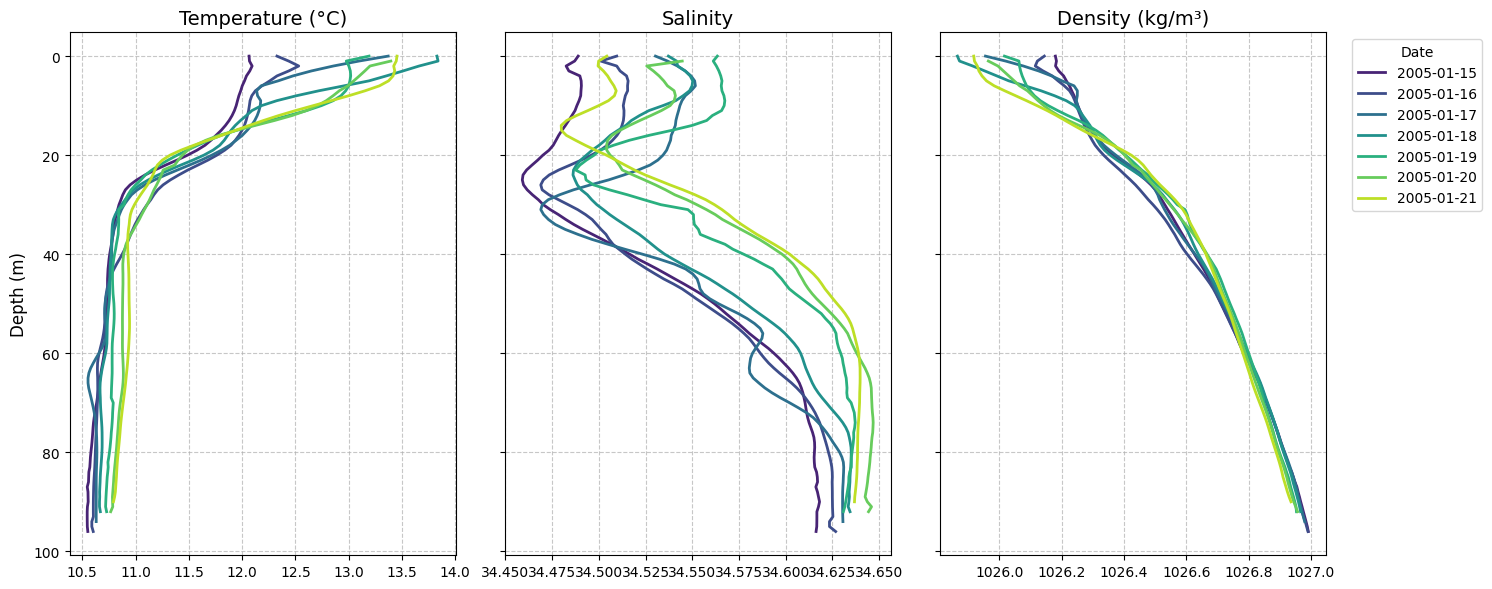

In [386]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Set up figure with shared y-axis
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

# 2. Define a sequential colormap for the 7 days (avoids default random colors)
colors = plt.cm.viridis(np.linspace(0.1, 0.9, 7))

# 3. Setup configurations for our loop
variables = ['temp', 'sal', 'dens']
titles = ['Temperature (°C)', 'Salinity', 'Density (kg/m³)']

# Loop through each subplot and variable
for idx, var in enumerate(variables):
    ax = axes[idx]

    # Loop through the days (indices 1 through 7)
    for i, color in zip(range(1, 8), colors):

        # Extract a clean date string for the legend (e.g., '2005-01-15')
        date_str = str(ds_daily_avg['time'].values[i])[:10]

        # Use xarray's .isel() for safer indexing regardless of dimension order
        data = ds_daily_avg[var].isel(time=i)
        depth = ds_daily_avg['depth']

        ax.plot(data, depth, label=date_str, color=color, linewidth=2)

    ax.set_title(titles[idx], fontsize=14)
    ax.grid(True, linestyle='--', alpha=0.7) # Softer grid lines

# 4. Format axes
axes[0].invert_yaxis() # Only need to invert once due to sharey=True
axes[0].set_ylabel('Depth (m)', fontsize=12)

# 5. Place a single legend outside the last plot
axes[-1].legend(title='Date', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout so the legend doesn't get cut off
plt.tight_layout()
plt.show()

In [402]:
# Create new variables in the dataset for smoothed temperature and salinity
# A 3-meter window is applied, centered on the current depth bin
ds_daily_avg['temp_smooth'] = ds_daily_avg['temp'].rolling(
    depth=3, center=True, min_periods=1
).mean()

ds_daily_avg['sal_smooth'] = ds_daily_avg['sal'].rolling(
    depth=3, center=True, min_periods=1
).mean()

# Add metadata attributes for clarity
ds_daily_avg['temp_smooth'].attrs['long_name'] = 'Smoothed Temperature (3m rolling mean)'
ds_daily_avg['sal_smooth'].attrs['long_name'] = 'Smoothed Salinity (3m rolling mean)'

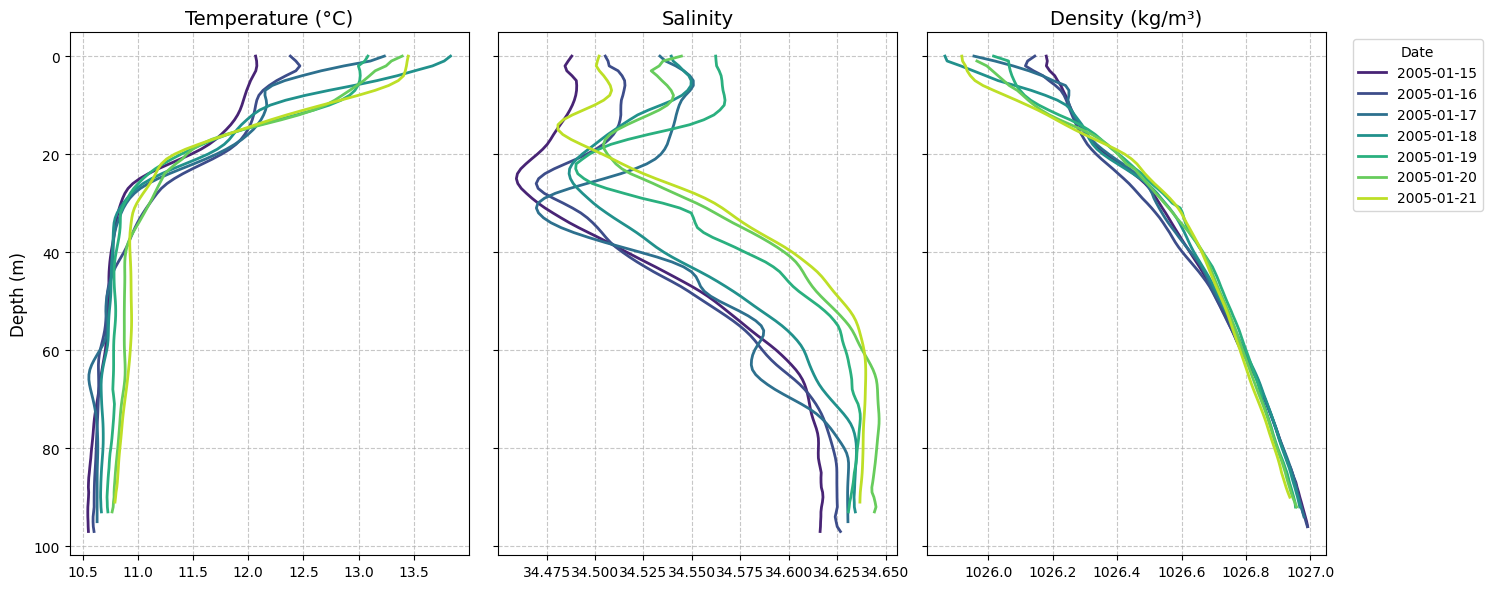

In [403]:

# 1. Set up figure with shared y-axis
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

# 2. Define a sequential colormap for the 7 days (avoids default random colors)
colors = plt.cm.viridis(np.linspace(0.1, 0.9, 7))

# 3. Setup configurations for our loop
variables = ['temp_smooth', 'sal_smooth', 'dens']
titles = ['Temperature (°C)', 'Salinity', 'Density (kg/m³)']

# Loop through each subplot and variable
for idx, var in enumerate(variables):
    ax = axes[idx]

    # Loop through the days (indices 1 through 7)
    for i, color in zip(range(1, 8), colors):

        # Extract a clean date string for the legend (e.g., '2005-01-15')
        date_str = str(ds_daily_avg['time'].values[i])[:10]

        # Use xarray's .isel() for safer indexing regardless of dimension order
        data = ds_daily_avg[var].isel(time=i)
        depth = ds_daily_avg['depth']

        ax.plot(data, depth, label=date_str, color=color, linewidth=2)

    ax.set_title(titles[idx], fontsize=14)
    ax.grid(True, linestyle='--', alpha=0.7) # Softer grid lines

# 4. Format axes
axes[0].invert_yaxis() # Only need to invert once due to sharey=True
axes[0].set_ylabel('Depth (m)', fontsize=12)

# 5. Place a single legend outside the last plot
axes[-1].legend(title='Date', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout so the legend doesn't get cut off
plt.tight_layout()
plt.show()

In [404]:
import gsw

# 1. Define location
lon, lat = -73.0, -36.8

# 2. Extract raw numpy arrays
p_vals = ds_daily_avg['depth'].values
sal_vals = ds_daily_avg['sal_smooth'].values
temp_vals = ds_daily_avg['temp_smooth'].values

# 3. Calculate Absolute Salinity (SA) and Conservative Temp (CT)
SA = gsw.SA_from_SP(sal_vals, p_vals, lon, lat)
CT = gsw.CT_from_t(SA, temp_vals, p_vals)

# 4. Calculate Brunt-Väisälä Frequency Squared (N2)
# gsw returns a 2D N2 array and a 2D p_mid array. We will ignore its 2D p_mid.
N2, _ = gsw.Nsquared(SA, CT, p_vals, lat=lat, axis=1)

# 5. FIX: Manually calculate the 1D depth midpoints
p_mid_1d = (p_vals[:-1] + p_vals[1:]) / 2

# 6. Add the new variable and 1D coordinate to the xarray Dataset
ds_daily_avg.coords['depth_mid'] = p_mid_1d
ds_daily_avg['N2'] = (('time', 'depth_mid'), N2)

# 7. Add helpful metadata attributes
ds_daily_avg['N2'].attrs['units'] = 'rad2 s-2'
ds_daily_avg['N2'].attrs['long_name'] = 'Brunt-Väisälä Frequency Squared'

In [469]:
ds_daily_avg

<xarray.Dataset> Size: 45kB
Dimensions:      (time: 9, depth: 101, pressure_bin: 101, depth_mid: 100)
Coordinates:
  * time         (time) datetime64[ns] 72B 2005-01-14 2005-01-15 ... 2005-01-22
    depth        (pressure_bin) int64 808B 0 1 2 3 4 5 6 ... 95 96 97 98 99 100
  * depth_mid    (depth_mid) float64 800B 0.5 1.5 2.5 3.5 ... 97.5 98.5 99.5
Dimensions without coordinates: pressure_bin
Data variables:
    dens         (time, depth) float64 7kB 1.026e+03 1.026e+03 ... nan nan
    temp         (time, depth) float64 7kB 11.6 11.6 11.69 11.69 ... nan nan nan
    sal          (time, depth) float64 7kB 34.54 34.55 34.56 ... nan nan nan
    N2           (time, depth_mid) float64 7kB -7.6e-06 1.757e-06 ... nan nan
    temp_smooth  (time, depth) float64 7kB 11.6 11.63 11.66 ... nan nan nan
    sal_smooth   (time, depth) float64 7kB 34.55 34.55 34.56 ... nan nan nan

In [473]:
# 1. Swap the underlying dimension so 'depth' becomes a proper indexed coordinate
ds_daily_avg = ds_daily_avg.swap_dims({'pressure_bin': 'depth'})

# 2. Now slice the dataset for depths between 1 and 52 meters
ds_daily_avg_52m = ds_daily_avg.sel(
    depth=slice(1, 52),
    depth_mid=slice(1, 52)
)

# View the dimensions of the new dataset to confirm
print(ds_daily_avg_52m)

<xarray.Dataset> Size: 23kB
Dimensions:      (time: 9, depth: 52, depth_mid: 51)
Coordinates:
  * time         (time) datetime64[ns] 72B 2005-01-14 2005-01-15 ... 2005-01-22
  * depth        (depth) int64 416B 1 2 3 4 5 6 7 8 ... 45 46 47 48 49 50 51 52
  * depth_mid    (depth_mid) float64 408B 1.5 2.5 3.5 4.5 ... 49.5 50.5 51.5
Data variables:
    dens         (time, depth) float64 4kB 1.026e+03 1.026e+03 ... 1.027e+03
    temp         (time, depth) float64 4kB 11.6 11.69 11.69 ... 10.94 10.94
    sal          (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63
    N2           (time, depth_mid) float64 4kB 1.757e-06 ... 1.725e-05
    temp_smooth  (time, depth) float64 4kB 11.63 11.66 11.69 ... 10.94 10.94
    sal_smooth   (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63


In [474]:
ds_daily_avg_52m

<xarray.Dataset> Size: 23kB
Dimensions:      (time: 9, depth: 52, depth_mid: 51)
Coordinates:
  * time         (time) datetime64[ns] 72B 2005-01-14 2005-01-15 ... 2005-01-22
  * depth        (depth) int64 416B 1 2 3 4 5 6 7 8 ... 45 46 47 48 49 50 51 52
  * depth_mid    (depth_mid) float64 408B 1.5 2.5 3.5 4.5 ... 49.5 50.5 51.5
Data variables:
    dens         (time, depth) float64 4kB 1.026e+03 1.026e+03 ... 1.027e+03
    temp         (time, depth) float64 4kB 11.6 11.69 11.69 ... 10.94 10.94
    sal          (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63
    N2           (time, depth_mid) float64 4kB 1.757e-06 ... 1.725e-05
    temp_smooth  (time, depth) float64 4kB 11.63 11.66 11.69 ... 10.94 10.94
    sal_smooth   (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63

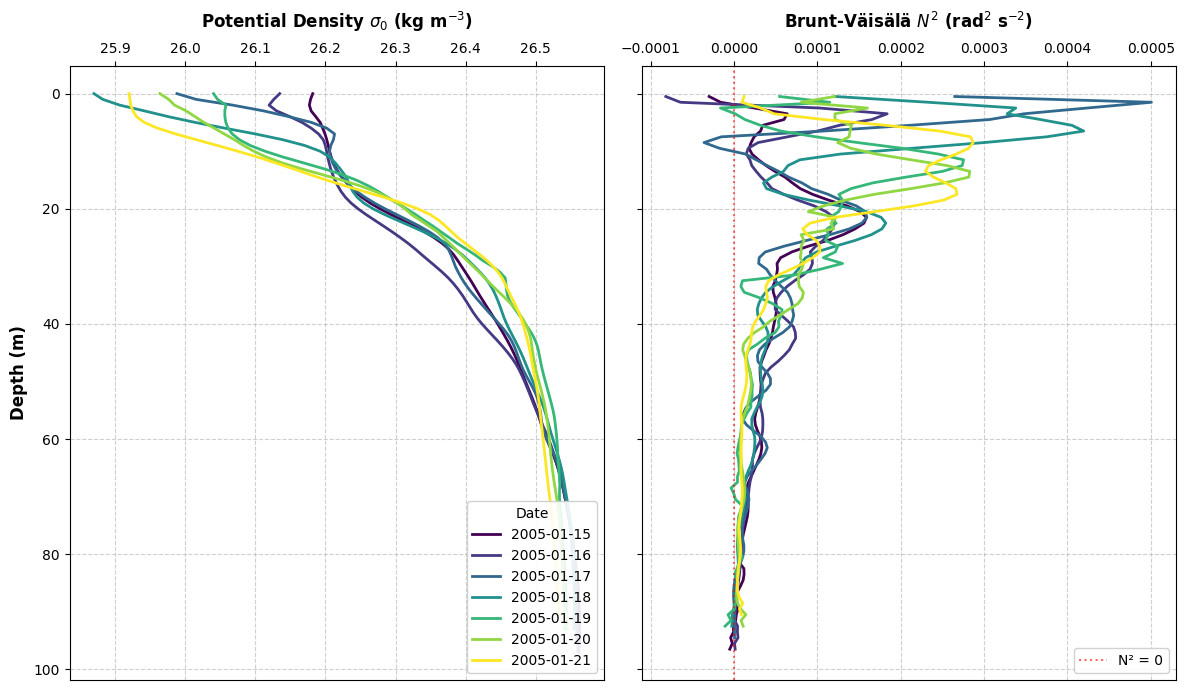

In [406]:
import matplotlib.pyplot as plt
import numpy as np
import gsw

# Create a figure with 2 subplots sharing the y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7), sharey=True)

# Generate a colormap to visualize the progression of time clearly
colors = plt.cm.viridis(np.linspace(0, 1, 7))

# Loop through the desired time indices (1 to 7) to match your previous plots
for idx, color in zip(range(1, 8), colors):

    # Safely select the specific day
    prof = ds_daily_avg.isel(time=idx)
    date_str = str(prof['time'].dt.strftime('%Y-%m-%d').values)

    # --- 1. DENSITY CALCULATION (using smoothed data) ---
    p = prof['depth'].values
    SA = gsw.SA_from_SP(prof['sal_smooth'].values, p, -73.0, -36.8)
    CT = gsw.CT_from_t(SA, prof['temp_smooth'].values, p)
    sig0 = gsw.sigma0(SA, CT)

    # --- PLOTTING ---
    ax1.plot(sig0, p, color=color, label=date_str, linewidth=2)
    ax2.plot(prof['N2'], prof['depth_mid'], color=color, linewidth=2)

# --- FORMATTING & AESTHETICS ---
ax1.set_xlabel(r'Potential Density $\sigma_0$ (kg m$^{-3}$)', fontsize=12, fontweight='bold', labelpad=10)
ax2.set_xlabel(r'Brunt-Väisälä $N^2$ (rad$^2$ s$^{-2}$)', fontsize=12, fontweight='bold', labelpad=10)

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.6)
    # Move x-axis labels/ticks to the top (standard for depth profiles)
    ax.xaxis.set_ticks_position('top')
    ax.xaxis.set_label_position('top')

# Invert the shared y-axis once
ax1.invert_yaxis()
ax1.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')

# Add a vertical zero-line to the N2 plot to easily identify unstable water (N2 < 0)
ax2.axvline(0, color='red', linestyle=':', alpha=0.6, linewidth=1.5, label='N² = 0')

# Place legends
ax1.legend(loc='lower right', title='Date', framealpha=0.9)
ax2.legend(loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

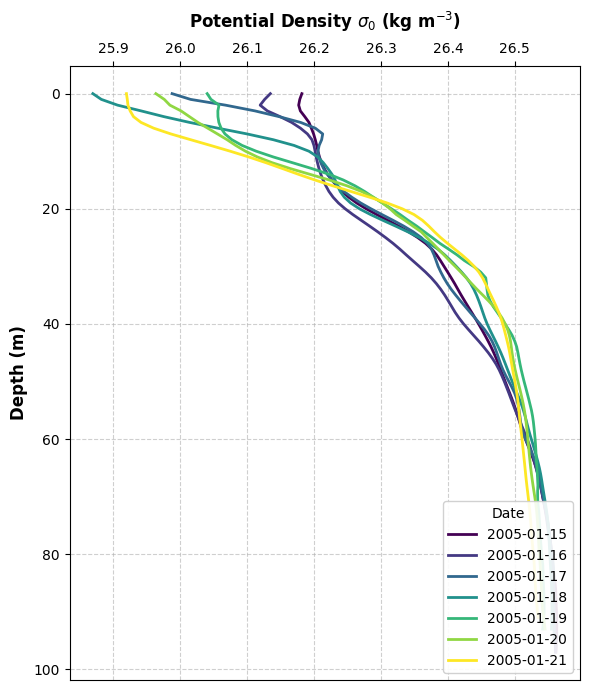

In [533]:
import matplotlib.pyplot as plt
import numpy as np
import gsw

# Create a figure with a single subplot
fig, ax1 = plt.subplots(figsize=(6, 7))

# Generate a colormap to visualize the progression of time clearly
colors = plt.cm.viridis(np.linspace(0, 1, 7))

# Loop through the desired time indices (1 to 7) to match your previous plots
for idx, color in zip(range(1, 8), colors):

    # Safely select the specific day
    prof = ds_daily_avg.isel(time=idx)
    date_str = str(prof['time'].dt.strftime('%Y-%m-%d').values)

    # --- DENSITY CALCULATION (using smoothed data) ---
    p = prof['depth'].values
    SA = gsw.SA_from_SP(prof['sal_smooth'].values, p, -73.0, -36.8)
    CT = gsw.CT_from_t(SA, prof['temp_smooth'].values, p)
    sig0 = gsw.sigma0(SA, CT)

    # --- PLOTTING ---
    ax1.plot(sig0, p, color=color, label=date_str, linewidth=2)

# --- FORMATTING & AESTHETICS ---
ax1.set_xlabel(r'Potential Density $\sigma_0$ (kg m$^{-3}$)', fontsize=12, fontweight='bold', labelpad=10)

ax1.grid(True, linestyle='--', alpha=0.6)
# Move x-axis labels/ticks to the top (standard for depth profiles)
ax1.xaxis.set_ticks_position('top')
ax1.xaxis.set_label_position('top')

# Invert the y-axis once
ax1.invert_yaxis()
ax1.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')

# Place legend
ax1.legend(loc='lower right', title='Date', framealpha=0.9)

plt.tight_layout()
plt.show()

In [407]:
#

In [21]:
!pip install multitaper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for multitaper: filename=multitaper-1.2.0-py3-none-any.whl size=1794320 sha256=9eaaab8d9ecdad685072ed085904248377a9d4146a57f3a10cc144bd51dc6a03
  Stored in directory: /root/.cache/pip/wheels/21/bd/ea/6e731f3f461db422b987a588f275db7724211675bc29c08ca7
Successfully built multitaper


In [408]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter
from multitaper import MTSpec
import pickle

In [409]:
import pickle

with open('/content/drive/MyDrive/@doctorado-sync/database/adcp-l1/dataB_h.pkl', 'rb') as f:
  dataB = pickle.load(f)

In [412]:
import numpy as np

def pca_time_depth(X):
    """
    X: array (ntime, ndepth). Returns PCs, EOFs, variance fraction.
    - Demeans each depth column.
    - Fills NaNs with 0 after demeaning (i.e., column mean).
    - Uses SVD on anomalies.
    """
    X = np.asarray(X, dtype=float)
    ntime, ndepth = X.shape

    # anomalies (demean columns)
    col_mean = np.nanmean(X, axis=0)
    Xa = X - col_mean

    # fill NaNs with 0 (column mean after demeaning)
    Xa = np.where(np.isnan(Xa), 0.0, Xa)

    # SVD: Xa = U S V^T
    U, S, VT = np.linalg.svd(Xa, full_matrices=False)
    V = VT.T

    # PCs (time series) and EOFs (vertical modes)
    PCs = U @ np.diag(S)          # (ntime, r)
    EOFs = V                      # (ndepth, r)

    # variance explained
    total_var = np.sum(np.var(Xa, axis=0, ddof=1))
    mode_var = (S**2) / (ntime - 1)
    var_frac = mode_var / total_var           # fraction per mode
    var_pct = 100 * var_frac

    return PCs, EOFs, var_frac, var_pct

In [413]:
u_PCs, u_EOFs, u_var_frac, u_var_pct = pca_time_depth(dataB['u'][:,0:52])
v_PCs, v_EOFs, v_var_frac, v_var_pct = pca_time_depth(dataB['v'][:,0:52])

for i, p in enumerate(u_var_pct[:5], start=1):
    print(f"Mode-U {i}: {p:.2f}%")
for i, p in enumerate(v_var_pct[:5], start=1):
    print(f"Mode-V {i}: {p:.2f}%")

Mode-U 1: 57.53%
Mode-U 2: 14.43%
Mode-U 3: 12.56%
Mode-U 4: 5.85%
Mode-U 5: 2.62%
Mode-V 1: 56.22%
Mode-V 2: 27.88%
Mode-V 3: 7.96%
Mode-V 4: 2.48%
Mode-V 5: 1.53%


In [414]:
k = 10
X_recon = u_PCs[:, :k] @ u_EOFs[:, :k].T  # anomalies
X_recon += np.nanmean(dataB['u'][:,0:52], axis=0)
dataB['u_re'] = X_recon
del X_recon

k = 10
X_recon = v_PCs[:, :k] @ v_EOFs[:, :k].T  # anomalies
X_recon += np.nanmean(dataB['v'][:,0:52], axis=0)
dataB['v_re'] = X_recon
del X_recon

In [437]:
u = dataB['u_re'].T/1000
v = dataB['v_re'].T/1000
time = dataB['time'].values
depth = dataB['depth'][0:52]-55

In [458]:
depth

array([-52., -51., -50., -49., -48., -47., -46., -45., -44., -43., -42.,
       -41., -40., -39., -38., -37., -36., -35., -34., -33., -32., -31.,
       -30., -29., -28., -27., -26., -25., -24., -23., -22., -21., -20.,
       -19., -18., -17., -16., -15., -14., -13., -12., -11., -10.,  -9.,
        -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.])

In [439]:
time

array(['2005-01-15T13:00:00.000000000', '2005-01-15T14:00:00.000000000',
       '2005-01-15T15:00:00.000000000', '2005-01-15T16:00:00.000000000',
       '2005-01-15T17:00:00.000000000', '2005-01-15T18:00:00.000000000',
       '2005-01-15T19:00:00.000000000', '2005-01-15T20:00:00.000000000',
       '2005-01-15T21:00:00.000000000', '2005-01-15T22:00:00.000000000',
       '2005-01-15T23:00:00.000000000', '2005-01-16T00:00:00.000000000',
       '2005-01-16T01:00:00.000000000', '2005-01-16T02:00:00.000000000',
       '2005-01-16T03:00:00.000000000', '2005-01-16T04:00:00.000000000',
       '2005-01-16T05:00:00.000000000', '2005-01-16T06:00:00.000000000',
       '2005-01-16T07:00:00.000000000', '2005-01-16T08:00:00.000000000',
       '2005-01-16T09:00:00.000000000', '2005-01-16T10:00:00.000000000',
       '2005-01-16T11:00:00.000000000', '2005-01-16T12:00:00.000000000',
       '2005-01-16T13:00:00.000000000', '2005-01-16T14:00:00.000000000',
       '2005-01-16T15:00:00.000000000', '2005-01-16

In [440]:
import xarray as xr
import pandas as pd
import numpy as np

ds_uv = xr.Dataset(
    data_vars={
        'u': (['depth', 'time'], u),
        'v': (['depth', 'time'], v)
    },
    coords={
        'depth': depth,
        'time': time
    }
)

# Add helpful metadata
ds_uv['u'].attrs = {'long_name': 'Eastward Velocity', 'units': 'm/s'}
ds_uv['v'].attrs = {'long_name': 'Northward Velocity', 'units': 'm/s'}
ds_uv['depth'].attrs = {'long_name': 'Depth', 'units': 'm'}

print(ds_uv)

<xarray.Dataset> Size: 205kB
Dimensions:  (depth: 52, time: 243)
Coordinates:
  * depth    (depth) float64 416B -52.0 -51.0 -50.0 -49.0 ... -3.0 -2.0 -1.0
  * time     (time) datetime64[ns] 2kB 2005-01-15T13:00:00 ... 2005-01-25T15:...
Data variables:
    u        (depth, time) float64 101kB -0.02563 -0.07214 ... 0.3385 0.3192
    v        (depth, time) float64 101kB -0.002107 -0.02534 ... 0.4287 0.259


In [441]:
ds_uv

<xarray.Dataset> Size: 205kB
Dimensions:  (depth: 52, time: 243)
Coordinates:
  * depth    (depth) float64 416B -52.0 -51.0 -50.0 -49.0 ... -3.0 -2.0 -1.0
  * time     (time) datetime64[ns] 2kB 2005-01-15T13:00:00 ... 2005-01-25T15:...
Data variables:
    u        (depth, time) float64 101kB -0.02563 -0.07214 ... 0.3385 0.3192
    v        (depth, time) float64 101kB -0.002107 -0.02534 ... 0.4287 0.259

In [442]:
# 1. Calculate the vertical derivatives of u and v with respect to depth
du_dz = ds_uv['u'].differentiate('depth')
dv_dz = ds_uv['v'].differentiate('depth')

# 2. Calculate the vertical shear squared (S2)
ds_uv['S2'] = (du_dz**2) + (dv_dz**2)

# 3. Add helpful metadata attributes
ds_uv['S2'].attrs['long_name'] = 'Vertical Shear Squared'
ds_uv['S2'].attrs['units'] = 's-2'



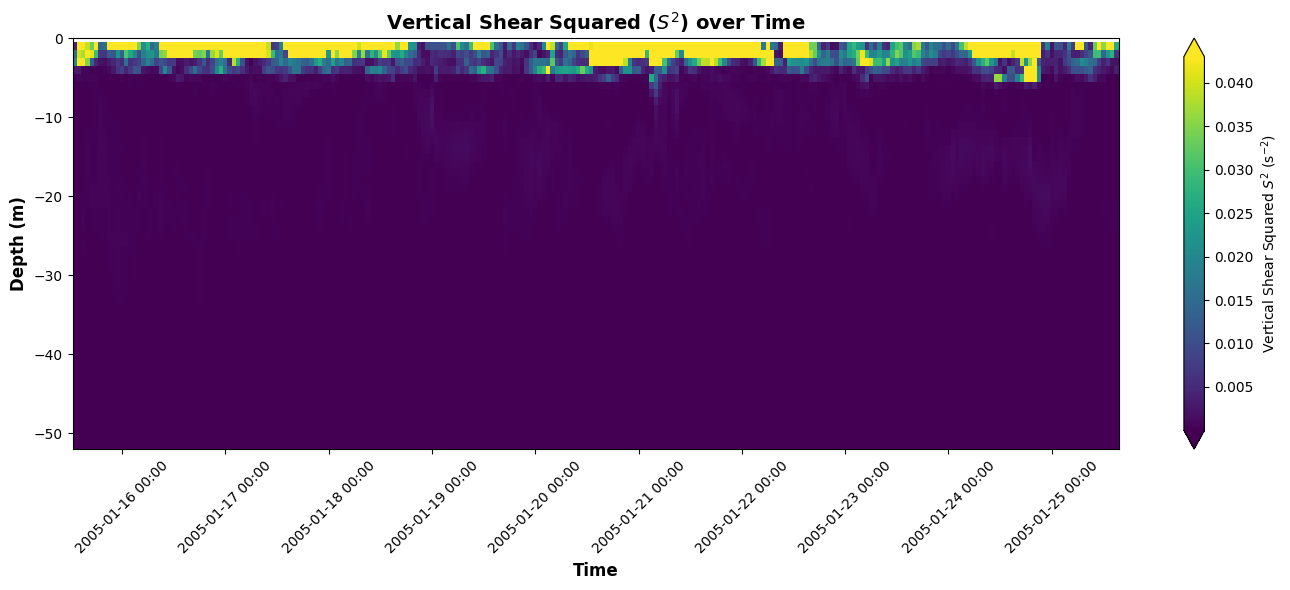

In [444]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 6))

# Plot the S2 variable
mesh = ds_uv['S2'].plot(
    ax=ax,
    x='time',
    y='depth',
    cmap='viridis',
    robust=True,
    cbar_kwargs={'label': r'Vertical Shear Squared $S^2$ (s$^{-2}$)'}
)

# FIX 1: Explicitly set the y-axis limits to put 0 at the top
ax.set_ylim(-52, 0)

# Format the time axis
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
plt.xticks(rotation=45)

ax.set_title('Vertical Shear Squared ($S^2$) over Time', fontsize=14, fontweight='bold')
ax.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')
ax.set_xlabel('Time', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [450]:
import numpy as np

# 1. Calculate the daily average of the dataset (u, v, and S2)
ds_daily_shear = ds_uv.resample(time='1D').mean()

In [446]:
ds_S2_extended

<xarray.Dataset> Size: 28kB
Dimensions:  (time: 11, depth: 101)
Coordinates:
  * time     (time) datetime64[ns] 88B 2005-01-15 2005-01-16 ... 2005-01-25
  * depth    (depth) int64 808B 0 1 2 3 4 5 6 7 8 ... 93 94 95 96 97 98 99 100
Data variables:
    u        (time, depth) float64 9kB nan nan nan nan nan ... nan nan nan nan
    v        (time, depth) float64 9kB nan nan nan nan nan ... nan nan nan nan
    S2       (time, depth) float64 9kB nan nan nan nan nan ... nan nan nan nan

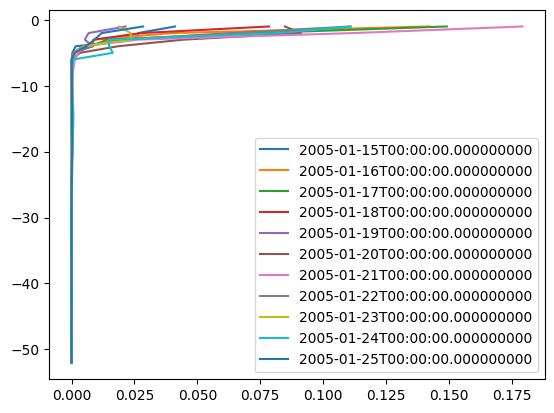

In [457]:
for i in range(0,11):
  plt.plot(ds_daily_shear['S2'][i,:],ds_daily_shear['depth'], label = ds_daily_shear['time'][i].values)
plt.legend()

In [460]:
ds_S2_clean = ds_daily_shear.where(ds_daily_shear['depth'] < -6)

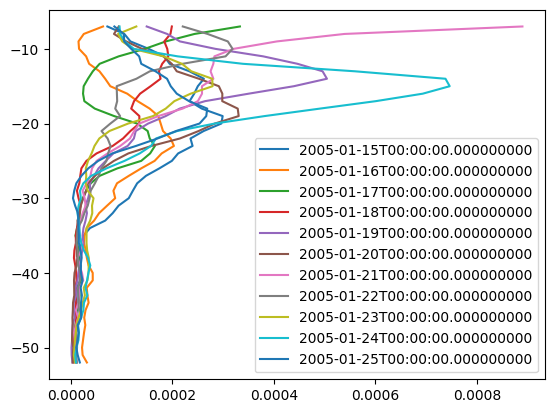

In [463]:
for i in range(0,11):
  plt.plot(ds_S2_clean['S2'][i,:],ds_S2_clean['depth'], label = ds_daily_shear['time'][i].values)
plt.legend()

In [464]:
ds_S2_clean


<xarray.Dataset> Size: 14kB
Dimensions:  (time: 11, depth: 52)
Coordinates:
  * time     (time) datetime64[ns] 88B 2005-01-15 2005-01-16 ... 2005-01-25
  * depth    (depth) float64 416B -52.0 -51.0 -50.0 -49.0 ... -3.0 -2.0 -1.0
Data variables:
    u        (time, depth) float64 5kB -0.0001668 -0.0007777 ... nan nan
    v        (time, depth) float64 5kB -0.07875 -0.07904 -0.07817 ... nan nan
    S2       (time, depth) float64 5kB 1.189e-05 7.163e-06 6.211e-06 ... nan nan

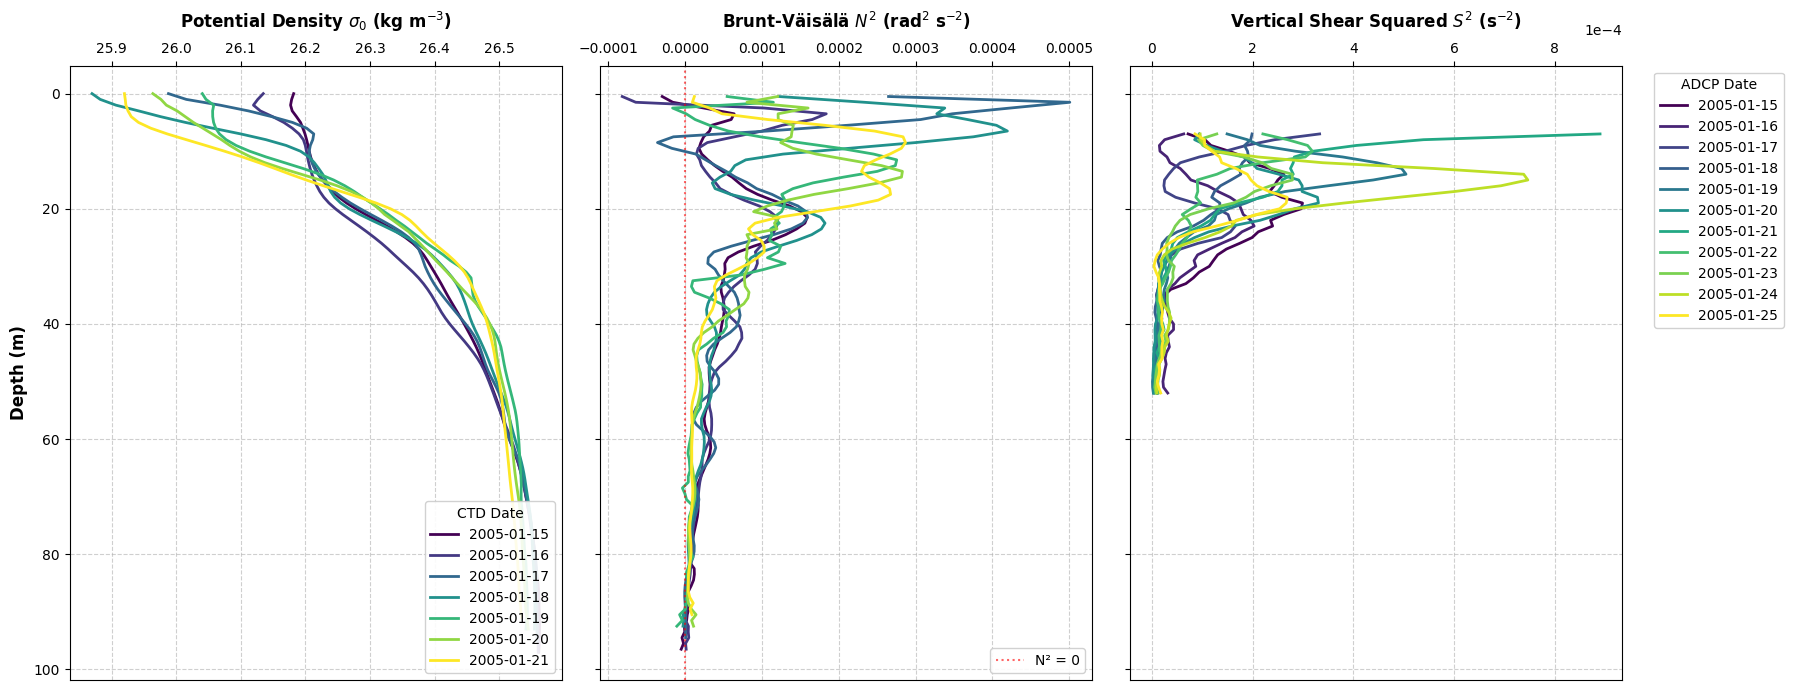

In [476]:
import matplotlib.pyplot as plt
import numpy as np
import gsw

# Create a figure with 3 subplots sharing the y-axis
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

# --- LEFT & CENTER PLOTS (CTD: Density and N2) ---
colors_ctd = plt.cm.viridis(np.linspace(0, 1, 7))

for idx, color in zip(range(1, 8), colors_ctd):
    prof = ds_daily_avg.isel(time=idx)
    date_str = str(prof['time'].dt.strftime('%Y-%m-%d').values)

    # Density calculation
    p = prof['depth'].values
    SA = gsw.SA_from_SP(prof['sal_smooth'].values, p, -73.0, -36.8)
    CT = gsw.CT_from_t(SA, prof['temp_smooth'].values, p)
    sig0 = gsw.sigma0(SA, CT)

    # Plotting Density and N2
    ax1.plot(sig0, p, color=color, label=date_str, linewidth=2)
    ax2.plot(prof['N2'], prof['depth_mid'], color=color, linewidth=2)

# --- RIGHT PLOT (ADCP: Shear Squared) ---
colors_shear = plt.cm.viridis(np.linspace(0, 1, 11))

for i, color in zip(range(0, 11), colors_shear):
    date_str_shear = str(ds_daily_shear['time'][i].values)[:10]

    # Plotting S2. Use np.abs() so negative ADCP depths align with positive CTD depths on the shared axis.
    ax3.plot(ds_S2_clean['S2'][i, :], np.abs(ds_S2_clean['depth']),
             label=date_str_shear, color=color, linewidth=2)

# --- FORMATTING & AESTHETICS ---
ax1.set_xlabel(r'Potential Density $\sigma_0$ (kg m$^{-3}$)', fontsize=12, fontweight='bold', labelpad=10)
ax2.set_xlabel(r'Brunt-Väisälä $N^2$ (rad$^2$ s$^{-2}$)', fontsize=12, fontweight='bold', labelpad=10)
ax3.set_xlabel(r'Vertical Shear Squared $S^2$ (s$^{-2}$)', fontsize=12, fontweight='bold', labelpad=10)

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.6)
    # Move x-axis labels/ticks to the top
    ax.xaxis.set_ticks_position('top')
    ax.xaxis.set_label_position('top')

# Apply scientific notation to the S2 axis for readability
ax3.ticklabel_format(style='sci', axis='x', scilimits=(0,0))

# Add a vertical zero-line to the N2 plot
ax2.axvline(0, color='red', linestyle=':', alpha=0.6, linewidth=1.5, label='N² = 0')

# Invert the shared y-axis once
ax1.invert_yaxis()
ax1.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')

# Place legends (moving the 11-day shear legend completely outside the plot area)
ax1.legend(loc='lower right', title='CTD Date', framealpha=0.9)
ax2.legend(loc='lower right', framealpha=0.9)
ax3.legend(title='ADCP Date', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.9)

plt.tight_layout()
plt.show()

In [478]:
ds_daily_avg_52m

<xarray.Dataset> Size: 23kB
Dimensions:      (time: 9, depth: 52, depth_mid: 51)
Coordinates:
  * time         (time) datetime64[ns] 72B 2005-01-14 2005-01-15 ... 2005-01-22
  * depth        (depth) int64 416B 1 2 3 4 5 6 7 8 ... 45 46 47 48 49 50 51 52
  * depth_mid    (depth_mid) float64 408B 1.5 2.5 3.5 4.5 ... 49.5 50.5 51.5
Data variables:
    dens         (time, depth) float64 4kB 1.026e+03 1.026e+03 ... 1.027e+03
    temp         (time, depth) float64 4kB 11.6 11.69 11.69 ... 10.94 10.94
    sal          (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63
    N2           (time, depth_mid) float64 4kB 1.757e-06 ... 1.725e-05
    temp_smooth  (time, depth) float64 4kB 11.63 11.66 11.69 ... 10.94 10.94
    sal_smooth   (time, depth) float64 4kB 34.55 34.56 34.57 ... 34.63 34.63

In [477]:
ds_S2_clean

<xarray.Dataset> Size: 14kB
Dimensions:  (time: 11, depth: 52)
Coordinates:
  * time     (time) datetime64[ns] 88B 2005-01-15 2005-01-16 ... 2005-01-25
  * depth    (depth) float64 416B -52.0 -51.0 -50.0 -49.0 ... -3.0 -2.0 -1.0
Data variables:
    u        (time, depth) float64 5kB -0.0001668 -0.0007777 ... nan nan
    v        (time, depth) float64 5kB -0.07875 -0.07904 -0.07817 ... nan nan
    S2       (time, depth) float64 5kB 1.189e-05 7.163e-06 6.211e-06 ... nan nan

In [488]:
ds_daily_avg_52m['N2'][1,:].values

array([-1.60745197e-05,  2.43425424e-05,  6.37852999e-05,  5.99583551e-05,
        3.45330051e-05,  3.18202731e-05,  2.41174577e-05,  2.05108174e-05,
        1.80288255e-05,  2.15849482e-05,  2.94621273e-05,  3.84316228e-05,
        4.90258481e-05,  6.11169124e-05,  6.99595430e-05,  7.95445220e-05,
        9.43376028e-05,  1.13460028e-04,  1.35793635e-04,  1.51356226e-04,
        1.58967368e-04,  1.55911387e-04,  1.45178833e-04,  1.30773208e-04,
        1.12364411e-04,  8.91846794e-05,  6.93396545e-05,  5.59017462e-05,
        5.15998430e-05,  5.21040166e-05,  5.10082716e-05,  4.95591424e-05,
        4.65497131e-05,  4.71208035e-05,  4.92721025e-05,  5.04359591e-05,
        5.10555366e-05,  5.02047842e-05,  4.87206852e-05,  4.72239760e-05,
        4.61035250e-05,  4.42872344e-05,  4.17961750e-05,  3.84137345e-05,
        3.58605967e-05,  3.31940906e-05,  3.12129405e-05,  3.12668245e-05,
        3.16863607e-05,  3.25097322e-05,  3.23290136e-05])

In [492]:
np.flip(ds_S2_clean['S2'][0,:].values)

array([           nan,            nan,            nan,            nan,
                  nan,            nan, 7.20670303e-05, 1.05452494e-04,
       1.17457256e-04, 1.53510616e-04, 1.84007286e-04, 1.94763596e-04,
       2.33608173e-04, 2.62195028e-04, 2.50184467e-04, 2.43005755e-04,
       2.33978883e-04, 2.58044754e-04, 2.99122779e-04, 2.96559190e-04,
       2.61711039e-04, 2.35777317e-04, 2.39835524e-04, 2.11433579e-04,
       1.99073710e-04, 1.74533728e-04, 1.48133272e-04, 1.30763782e-04,
       1.22236234e-04, 1.14193148e-04, 9.41087053e-05, 8.25405303e-05,
       6.77569490e-05, 3.77683986e-05, 2.53988146e-05, 2.18491845e-05,
       1.63285507e-05, 1.63145963e-05, 1.99735029e-05, 1.91238624e-05,
       1.85180024e-05, 1.22874078e-05, 1.14010951e-05, 1.19304387e-05,
       1.26806285e-05, 1.26136141e-05, 1.13071615e-05, 1.04746488e-05,
       7.30846025e-06, 6.21096916e-06, 7.16340166e-06, 1.18905887e-05])

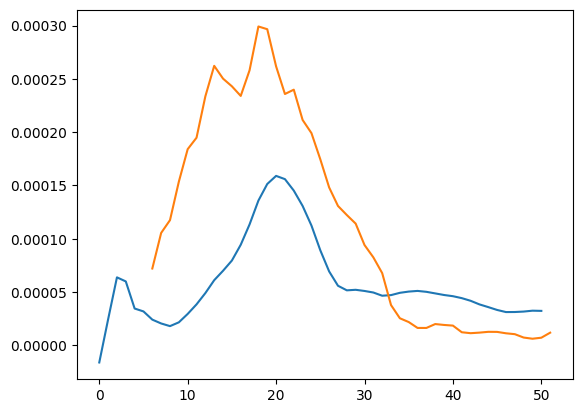

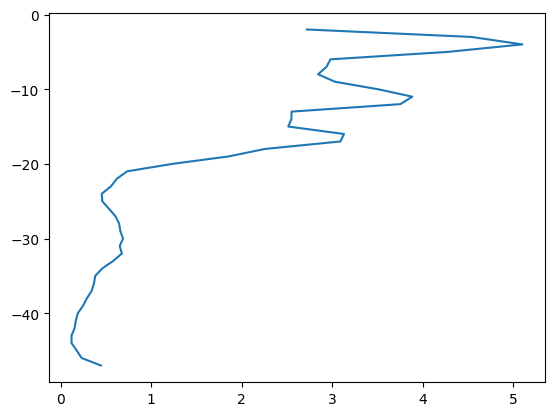

In [497]:
plt.plot(ds_daily_avg_52m['N2'][1,:])
plt.plot(np.flip(ds_S2_clean['S2'][0,:]))
plt.figure()
plt.plot(ds_daily_avg_52m['N2'][1,:].values / np.flip(ds_S2_clean['S2'][0,0:51].values),ds_S2_clean['depth'][0:51])

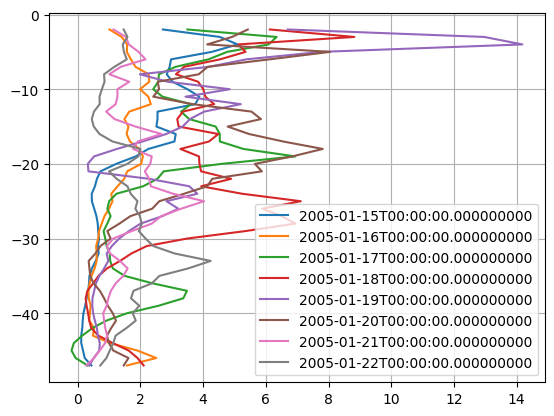

In [505]:
for i in range(0,8):
  plt.plot(ds_daily_avg_52m['N2'][i+1,:].values / np.flip(ds_S2_clean['S2'][i,0:51].values),ds_S2_clean['depth'][0:51], label =  ds_S2_clean['time'][i].values)
plt.grid()
plt.legend()

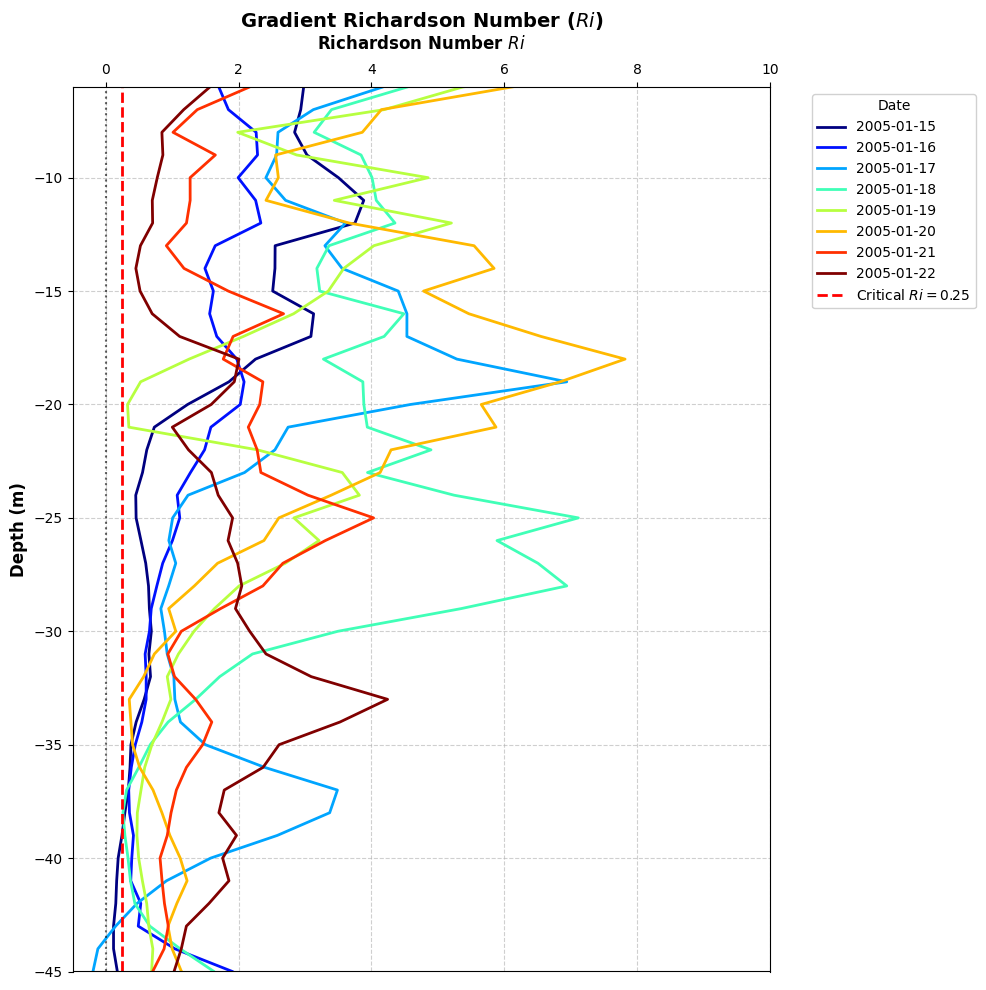

In [511]:
import matplotlib.pyplot as plt
import numpy as np

# Set up a professional, vertically oriented figure
fig, ax = plt.subplots(figsize=(10, 10))

# Generate a sequential colormap
colors = plt.cm.jet(np.linspace(0, 1, 8))

for i, color in zip(range(0, 8), colors):
    # Format the timestamp for a clean legend label
    date_str = str(ds_S2_clean['time'][i].values)[:10]

    # Calculate Ri using your exact indexing and flipping logic
    Ri = ds_daily_avg_52m['N2'][i+1, :].values / np.flip(ds_S2_clean['S2'][i, 0:51].values)
    depth = ds_S2_clean['depth'][0:51]

    # Plot the profile
    ax.plot(Ri, depth, label=date_str, color=color, linewidth=2)

# --- PHYSICAL THRESHOLDS ---
# The critical Richardson number (Ri = 0.25)
ax.axvline(0.25, color='red', linestyle='--', linewidth=2, label=r'Critical $Ri = 0.25$')
# A zero-line to distinguish static instability (N2 < 0)
ax.axvline(0, color='black', linestyle=':', linewidth=1.5, alpha=0.6)

# --- FORMATTING & AESTHETICS ---
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_title('Gradient Richardson Number ($Ri$)', fontsize=14, fontweight='bold')
ax.set_xlabel(r'Richardson Number $Ri$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')

# Focus the x-axis on the dynamically important range
# This cuts off the near-infinite values in the deep, low-shear water
ax.set_xlim(-0.5, 10)

# Ensure the depth axis correctly places the surface at the top
# (Adjust these limits if your masked array differs slightly)
ax.set_ylim(-45, -6)

# Move x-axis labels to the top for standard depth-profile styling
ax.xaxis.set_ticks_position('top')
ax.xaxis.set_label_position('top')

# Place the legend cleanly outside the plot
ax.legend(title='Date', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.9)

plt.tight_layout()
plt.show()

In [512]:
#

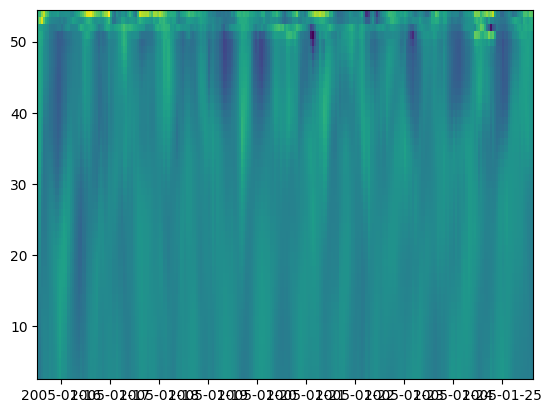

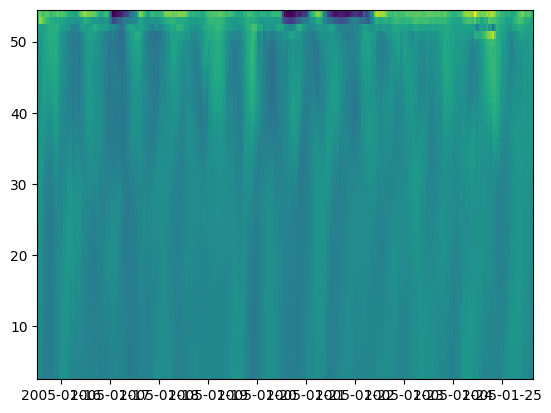

In [513]:
plt.figure()
plt.pcolor(dataB['time'],dataB['depth'][0:52],dataB['u_re'].T)

plt.figure()
plt.pcolor(dataB['time'],dataB['depth'][0:52],dataB['v_re'].T)

In [281]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = dataB['u_re']/1000
v_re = dataB['v_re']/1000

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2 = (du_dz**2) + (dv_dz**2)

print(f"Shape of du_dz: {du_dz.shape}")
print(f"Shape of dv_dz: {dv_dz.shape}")
print(f"Shape of S2 (Shear Squared): {S2.shape}")

# You can now further analyze or plot S2

Shape of du_dz: (243, 52)
Shape of dv_dz: (243, 52)
Shape of S2 (Shear Squared): (243, 52)


In [282]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = u_re2_nios
v_re = v_re2_nios

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2_nios = (du_dz**2) + (dv_dz**2)




In [283]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = u_re2_diurnal
v_re = v_re2_diurnal

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2_diurnal = (du_dz**2) + (dv_dz**2)

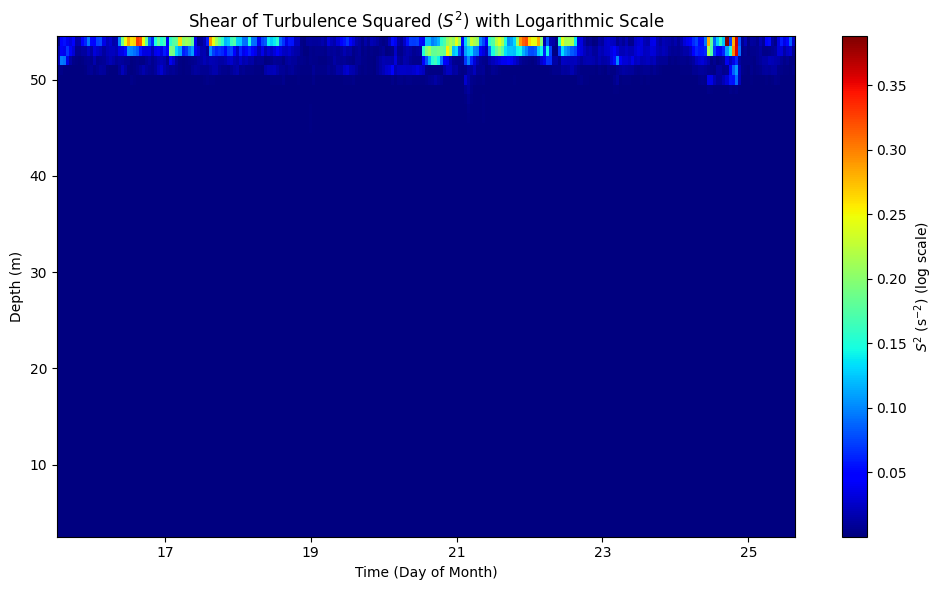

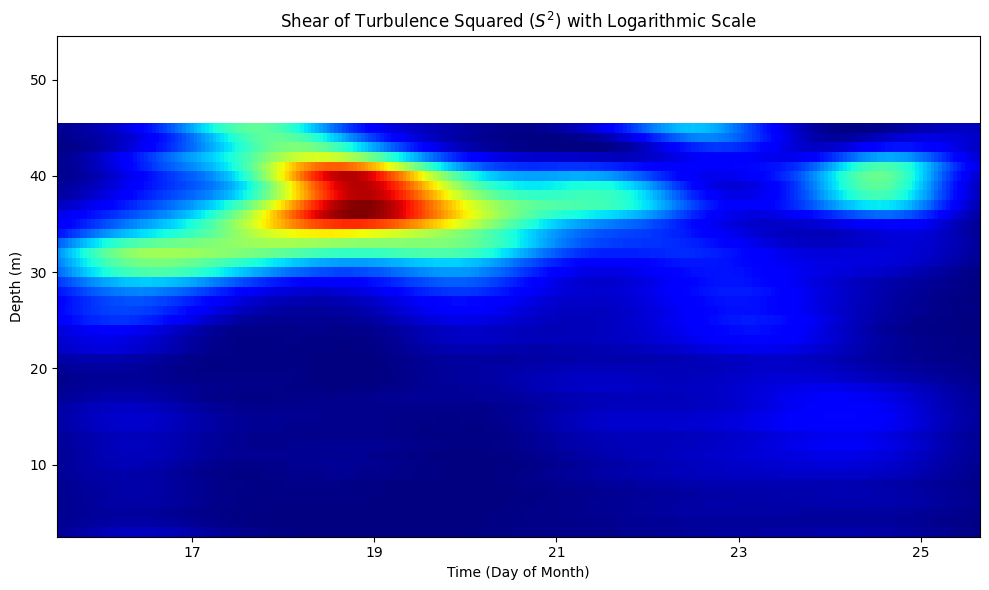

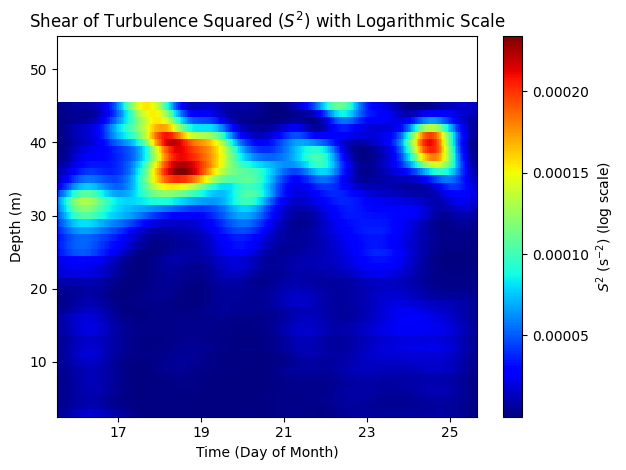

In [286]:
import matplotlib.colors as colors

plt.figure(figsize=(10, 6)) # Create a new figure for better control
plt.pcolormesh(dataB['time'], dataB['depth'][0:52], S2.T, cmap='jet')
plt.colorbar(label='$S^2$ (s$^{-2}$) (log scale)')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) with Logarithmic Scale')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()


plt.figure(figsize=(10, 6)) # Create a new figure for better control
plt.pcolormesh(dataB['time'], dataB['depth'][0:52], S2_nios.T, cmap='jet')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) with Logarithmic Scale')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()


plt.pcolormesh(dataB['time'], dataB['depth'][0:52], S2_diurnal.T, cmap='jet')
plt.colorbar(label='$S^2$ (s$^{-2}$) (log scale)')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) with Logarithmic Scale')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

/tmp/ipykernel_781/3306940122.py:1: RuntimeWarning: Mean of empty slice
  plt.plot(np.nanmean(S2_diurnal,axis = 0), S2_DEPTH, label = 'Diurnal')
/tmp/ipykernel_781/3306940122.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.nanmean(S2_nios,axis = 0), S2_DEPTH, label = 'Inertial')


Text(0.5, 0, 'Value (s$^{2}$)')

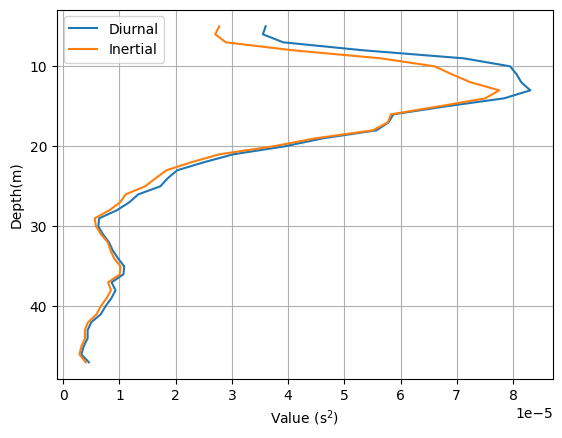

In [336]:
plt.plot(np.nanmean(S2_diurnal,axis = 0), S2_DEPTH, label = 'Diurnal')
plt.plot(np.nanmean(S2_nios,axis = 0), S2_DEPTH, label = 'Inertial')
plt.gca().invert_yaxis()
plt.legend()
plt.ylabel('Depth(m)')
plt.grid()
plt.xlabel(r'Value (s$^{2}$)')

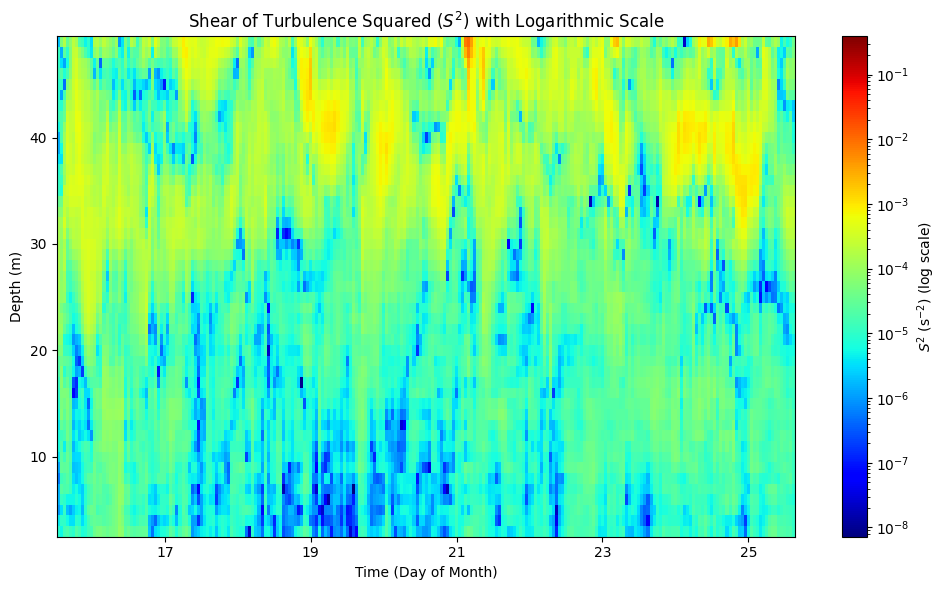

In [78]:
plt.figure(figsize=(10, 6)) # Create a new figure for better control
plt.pcolormesh(dataB['time'], dataB['depth'][0:47], S2[:,0:47].T, cmap='jet', norm=colors.LogNorm(vmin=S2[S2 > 0].min(), vmax=S2.max()))
plt.colorbar(label='$S^2$ (s$^{-2}$) (log scale)')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) with Logarithmic Scale')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.savefig('/content/1.png') # Save the plot to the specified file
plt.show()

In [82]:
!pip install utide

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.3/75.3 kB 2.2 MB/s eta 0:00:00


In [83]:
from utide import solve, reconstruct

In [84]:
u_re2 = dataB['u_re']
v_re2 = dataB['v_re']
t2 = dataB['time']

In [89]:
u_re2_tide = np.full((243, 52), np.nan)
v_re2_tide = np.full((243, 52), np.nan)

for i1 in range(0,52):

    x = u_re2[:,i1]
    y = v_re2[:,i1]
    coef = solve(
        t2, x, y,
        lat=-36.4,
        nodal=False,
        trend=False,
        method='ols',
        conf_int='linear',
        Rayleigh_min=0.95,
        verbose=False
    );
    tide = reconstruct(t2, coef, verbose=False);

    u_re2_tide[:,i1] = tide['u']
    v_re2_tide[:,i1] = tide['v']

/tmp/ipykernel_781/962132044.py:37: RuntimeWarning: Mean of empty slice
  ax2.plot(np.nanmean(S2_diurnal, axis=0), S2_DEPTH, label='Diurnal', linewidth=2)
/tmp/ipykernel_781/962132044.py:38: RuntimeWarning: Mean of empty slice
  ax2.plot(np.nanmean(S2_nios, axis=0), S2_DEPTH, label='Inertial', linewidth=2)


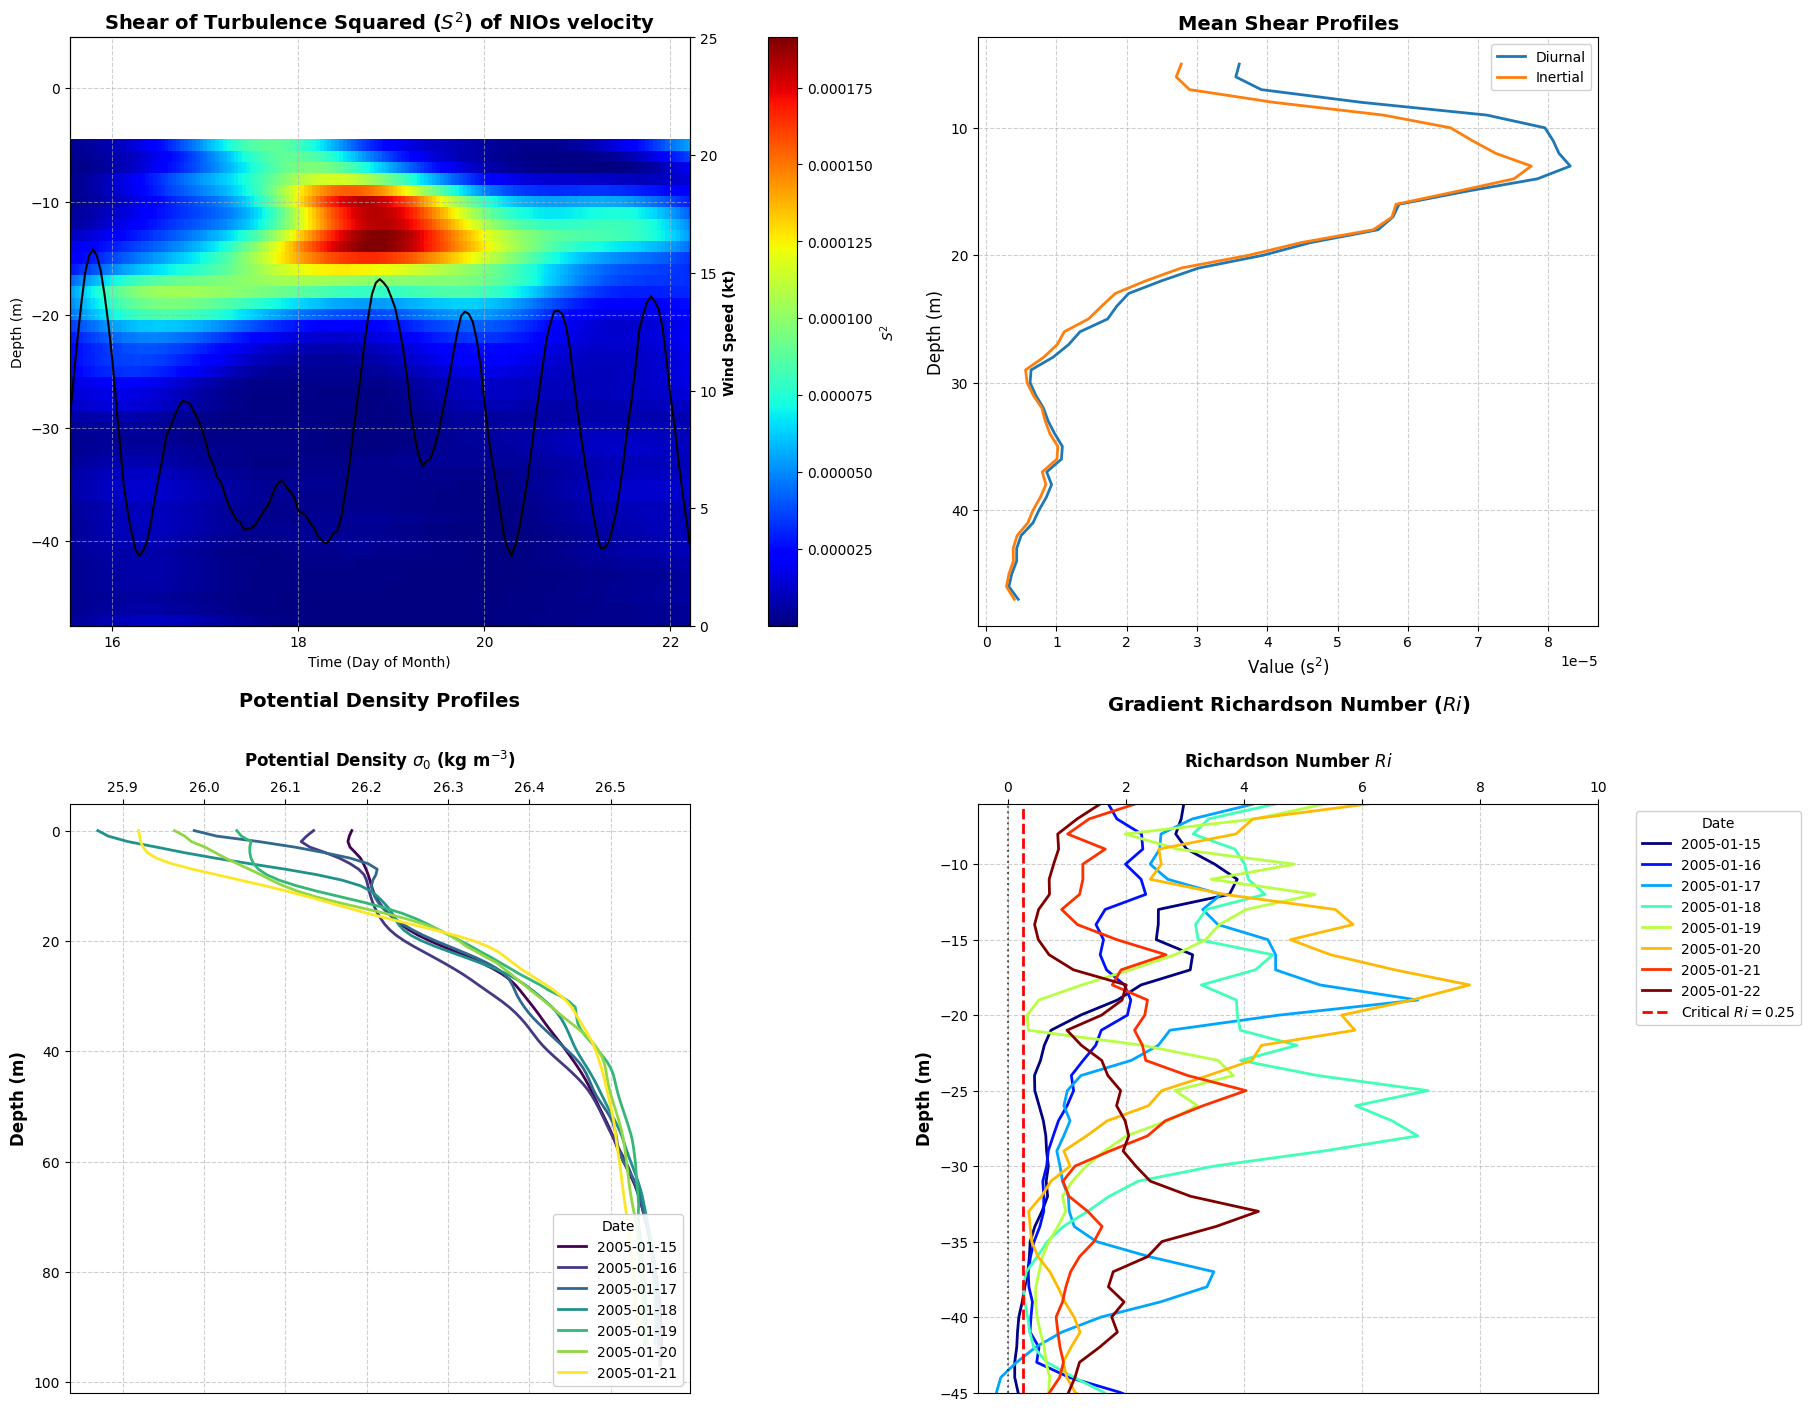

In [534]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import gsw
from scipy.signal import savgol_filter

# Create a 2x2 grid for the subplots with constrained layout to handle spacing automatically
fig, axes = plt.subplots(2, 2, figsize=(18, 14), constrained_layout=True)

# Flatten the axes array for easy assignment
ax1, ax2, ax3, ax4 = axes.flatten()

# ==========================================
# SUBPANEL 1 (Top Left): S2 Pcolormesh & Wind
# ==========================================
# Pcolormesh on the primary y-axis
c1 = ax1.pcolormesh(dataB['time'], dataB['depth'][0:52]-50, S2_nios[:,0:52].T, cmap='jet', shading='auto')
fig.colorbar(c1, ax=ax1, label='$S^2$')
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
ax1.set_xlabel('Time (Day of Month)')
ax1.set_ylabel('Depth (m)')
ax1.set_title('Shear of Turbulence Squared ($S^2$) of NIOs velocity', fontsize=14, fontweight='bold')
ax1.set_xlim(dataB['time'][0], dataB['time'][160])
ax1.grid(True, linestyle='--', alpha=0.6)

# Wind speed on the secondary y-axis (twinx)
ax1_twin = ax1.twinx()
ax1_twin.plot(cs['time'], savgol_filter(cs['wind_speed_kt'], 20, 2), color='k')
ax1_twin.set_ylim([0, 25])
ax1_twin.set_ylabel('Wind Speed (kt)', fontweight='bold')


# ==========================================
# SUBPANEL 2 (Top Right): Mean Shear Profiles
# ==========================================
ax2.plot(np.nanmean(S2_diurnal, axis=0), S2_DEPTH, label='Diurnal', linewidth=2)
ax2.plot(np.nanmean(S2_nios, axis=0), S2_DEPTH, label='Inertial', linewidth=2)
ax2.invert_yaxis()
ax2.set_xlabel(r'Value (s$^{2}$)', fontsize=12)
ax2.set_ylabel('Depth (m)', fontsize=12)
ax2.set_title('Mean Shear Profiles', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(framealpha=0.9)


# ==========================================
# SUBPANEL 3 (Bottom Left): Potential Density
# ==========================================
colors3 = plt.cm.viridis(np.linspace(0, 1, 7))

for idx, color in zip(range(1, 8), colors3):
    prof = ds_daily_avg.isel(time=idx)
    date_str = str(prof['time'].dt.strftime('%Y-%m-%d').values)

    p = prof['depth'].values
    SA = gsw.SA_from_SP(prof['sal_smooth'].values, p, -73.0, -36.8)
    CT = gsw.CT_from_t(SA, prof['temp_smooth'].values, p)
    sig0 = gsw.sigma0(SA, CT)

    ax3.plot(sig0, p, color=color, label=date_str, linewidth=2)

ax3.set_xlabel(r'Potential Density $\sigma_0$ (kg m$^{-3}$)', fontsize=12, fontweight='bold', labelpad=10)
ax3.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')
ax3.set_title('Potential Density Profiles', fontsize=14, fontweight='bold', pad=30)
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.xaxis.set_ticks_position('top')
ax3.xaxis.set_label_position('top')
ax3.invert_yaxis()
ax3.legend(loc='lower right', title='Date', framealpha=0.9)


# ==========================================
# SUBPANEL 4 (Bottom Right): Richardson Number
# ==========================================
colors4 = plt.cm.jet(np.linspace(0, 1, 8))

for i, color in zip(range(0, 8), colors4):
    date_str = str(ds_S2_clean['time'][i].values)[:10]

    Ri = ds_daily_avg_52m['N2'][i+1, :].values / np.flip(ds_S2_clean['S2'][i, 0:51].values)
    depth = ds_S2_clean['depth'][0:51]

    ax4.plot(Ri, depth, label=date_str, color=color, linewidth=2)

# Physical Thresholds
ax4.axvline(0.25, color='red', linestyle='--', linewidth=2, label=r'Critical $Ri = 0.25$')
ax4.axvline(0, color='black', linestyle=':', linewidth=1.5, alpha=0.6)

ax4.set_title('Gradient Richardson Number ($Ri$)', fontsize=14, fontweight='bold', pad=30)
ax4.set_xlabel(r'Richardson Number $Ri$', fontsize=12, fontweight='bold', labelpad=10)
ax4.set_ylabel('Depth (m)', fontsize=12, fontweight='bold')
ax4.set_xlim(-0.5, 10)
ax4.set_ylim(-45, -6)
ax4.xaxis.set_ticks_position('top')
ax4.xaxis.set_label_position('top')
ax4.grid(True, linestyle='--', alpha=0.6)

# Place the legend outside the plot box so it doesn't overlap the deep water data
ax4.legend(title='Date', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.9)

plt.show()

In [90]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = dataB['u_re']/1000 - u_re2_tide/1000
v_re = dataB['v_re']/1000 - v_re2_tide/1000

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2 = (du_dz**2) + (dv_dz**2)

print(f"Shape of du_dz: {du_dz.shape}")
print(f"Shape of dv_dz: {dv_dz.shape}")
print(f"Shape of S2 (Shear Squared): {S2.shape}")

# You can now further analyze or plot S2

Shape of du_dz: (243, 52)
Shape of dv_dz: (243, 52)
Shape of S2 (Shear Squared): (243, 52)


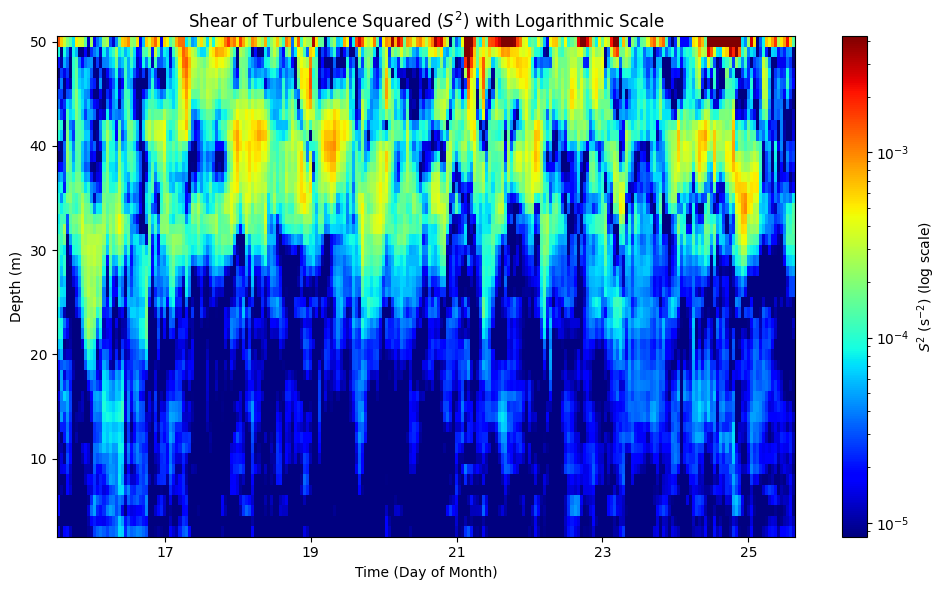

In [103]:
plt.figure(figsize=(10, 6)) # Create a new figure for better control
plt.pcolormesh(dataB['time'], dataB['depth'][0:48], S2[:,0:48].T, cmap='jet', norm=colors.LogNorm(vmin=S2[S2 > 0].min()/0.001, vmax=S2.max()/100))
plt.colorbar(label='$S^2$ (s$^{-2}$) (log scale)')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) with Logarithmic Scale')
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

In [126]:
!pip install netCDF4 xarray numpy seaborn matplotlib scipy multitaper clouddrift jupyter

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.5/134.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 990.1/990.1 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.8/698.8 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━

In [514]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

u_re2_diurnal = np.full((243, 52), np.nan)
v_re2_diurnal = np.full((243, 52), np.nan)

for i in range(0,44):

    dt = 1/24
    P = 2
    x = u_re2[:,i]/1000
    y = v_re2[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 2
    period = 22/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    u_re2_diurnal[:,i] = cvo.real
    v_re2_diurnal[:,i] = cvo.imag

In [515]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = u_re2_diurnal
v_re = v_re2_diurnal

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2 = (du_dz**2) + (dv_dz**2)

print(f"Shape of du_dz: {du_dz.shape}")
print(f"Shape of dv_dz: {dv_dz.shape}")
print(f"Shape of S2 (Shear Squared): {S2.shape}")

# You can now further analyze or plot S2

Shape of du_dz: (243, 52)
Shape of dv_dz: (243, 52)
Shape of S2 (Shear Squared): (243, 52)


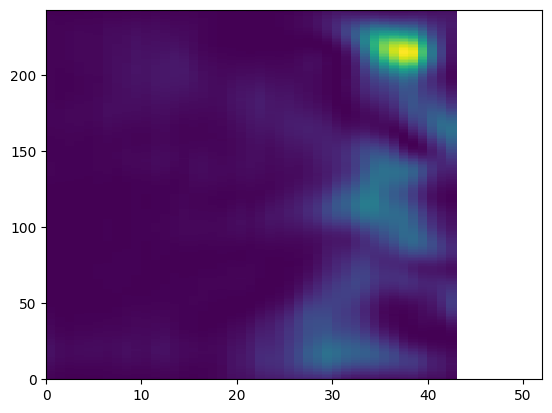

In [516]:
plt.pcolor(S2)

Text(0.5, 1.0, '@Rec-Near-Diurnal')

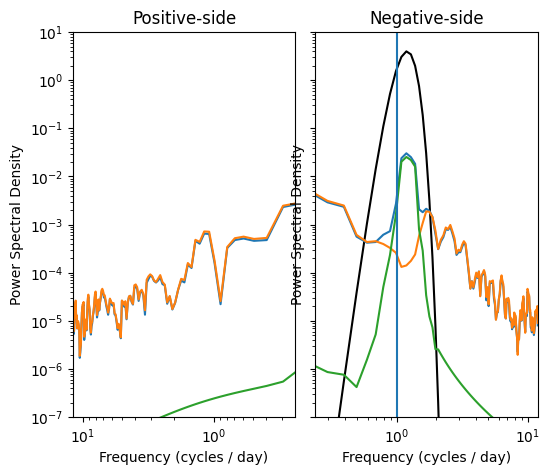

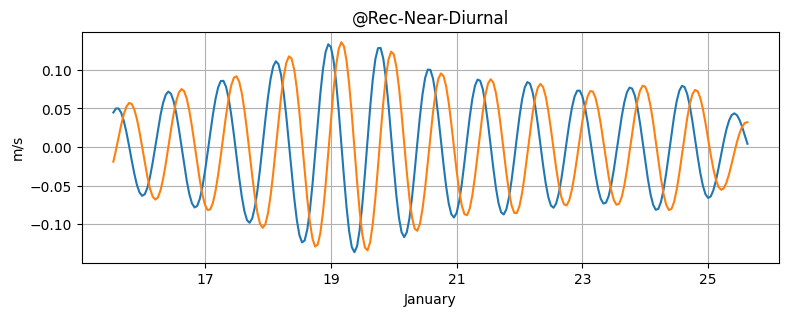

In [517]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

dt = 1/24
P = 2
x = u_re2[:,40]/1000 - u_re2_tide[:,40]/1000
y = v_re2[:,40]/1000 - v_re2_tide[:,40]/1000
cv = x + 1j * y
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)

gamma = 3
beta = 10
period = 20/24 #period you're interested in. Here it's the M2 tide,
omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

_, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
psif = psif[0,0]
cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
#cvo, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))
cvr = cv - cvo

spec = MTSpec(cvo, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So = np.ravel(spec.spec)

spec = MTSpec(cvr, nw=P, dt=dt, iadapt=1, nfft=len(cv))
Sr = np.ravel(spec.spec)

fig, ax = plt.subplots(1, 2, figsize=(6, 5), sharey=True, gridspec_kw={"wspace": 0.09})

ax[0].loglog(-f[f<0],S[f<0])#plot negative side
ax[0].loglog(-f[f<0],Sr[f<0])#plot negative side
ax[0].loglog(-f[f<0],So[f<0])#plot negative side

ax[0].set_xlabel("Frequency (cycles / day)")
ax[0].set_ylabel("Power Spectral Density")
ax[0].set_xlim(np.max(f)/50, np.max(f))
ax[0].set_ylim(10e-8, 10e0)
ax[0].invert_xaxis()
ax[0].set_title("Positive-side")

ax[1].loglog(f[f>0], 1*np.abs(psif[f>0])**2, color="black")
ax[1].loglog(f[f>0],S[f>0])#plot positive side
ax[1].loglog(f[f>0],Sr[f>0])#plot positive side
ax[1].loglog(f[f>0],So[f>0])#plot positive side

ax[1].set_xlabel("Frequency (cycles / day)")
ax[1].set_ylabel("Power Spectral Density")
ax[1].set_xlim(np.max(f)/50, np.max(f))
ax[1].set_ylim(10e-8, 10e0)
ax[1].set_title("Negative-side")
ax[1].axvline(1)

#------------

plt.figure(figsize=(9,3))
plt.plot(t2,cvo.real)
plt.plot(t2,cvo.imag)
plt.grid()
plt.ylabel('m/s')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel(dataB['time'][50].strftime('%B'))
plt.title('@Rec-Near-Diurnal')

Text(0.5, 1.0, '@Rec-Near-Diurnal')

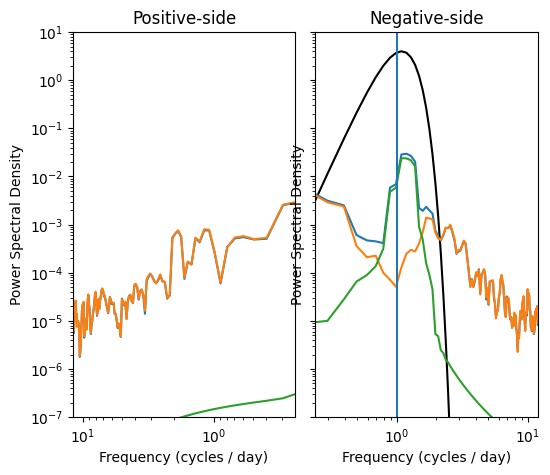

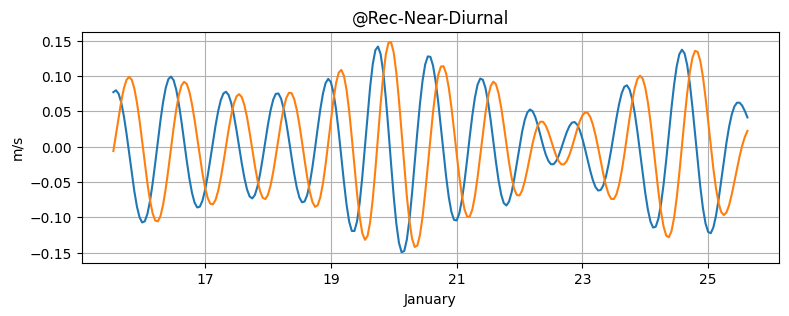

In [518]:
import clouddrift.wavelet as wt
from scipy import signal, ndimage

dt = 1/24
P = 2
x = u_re2[:,40]/1000
y = v_re2[:,40]/1000
cv = x + 1j * y
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)

gamma = 3
beta = 3
period = 22/24 #period you're interested in. Here it's the M2 tide,
omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

_, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
psif = psif[0,0]
cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
#cvo, _ = np.conj(wt.morse_wavelet_transform(np.conj(cv),gamma,beta,[omega],complex=True,boundary="mirror"))
cvr = cv - cvo

spec = MTSpec(cvo, nw=P, dt=dt, iadapt=1, nfft=len(cv))
So = np.ravel(spec.spec)

spec = MTSpec(cvr, nw=P, dt=dt, iadapt=1, nfft=len(cv))
Sr = np.ravel(spec.spec)

fig, ax = plt.subplots(1, 2, figsize=(6, 5), sharey=True, gridspec_kw={"wspace": 0.09})

ax[0].loglog(-f[f<0],S[f<0])#plot negative side
ax[0].loglog(-f[f<0],Sr[f<0])#plot negative side
ax[0].loglog(-f[f<0],So[f<0])#plot negative side

ax[0].set_xlabel("Frequency (cycles / day)")
ax[0].set_ylabel("Power Spectral Density")
ax[0].set_xlim(np.max(f)/50, np.max(f))
ax[0].set_ylim(10e-8, 10e0)
ax[0].invert_xaxis()
ax[0].set_title("Positive-side")

ax[1].loglog(f[f>0], 1*np.abs(psif[f>0])**2, color="black")
ax[1].loglog(f[f>0],S[f>0])#plot positive side
ax[1].loglog(f[f>0],Sr[f>0])#plot positive side
ax[1].loglog(f[f>0],So[f>0])#plot positive side

ax[1].set_xlabel("Frequency (cycles / day)")
ax[1].set_ylabel("Power Spectral Density")
ax[1].set_xlim(np.max(f)/50, np.max(f))
ax[1].set_ylim(10e-8, 10e0)
ax[1].set_title("Negative-side")
ax[1].axvline(1)

#------------

plt.figure(figsize=(9,3))
plt.plot(t2,cvo.real)
plt.plot(t2,cvo.imag)
plt.grid()
plt.ylabel('m/s')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel(dataB['time'][50].strftime('%B'))
plt.title('@Rec-Near-Diurnal')

Text(0.5, 0, 'Frequency (cycles/day)')

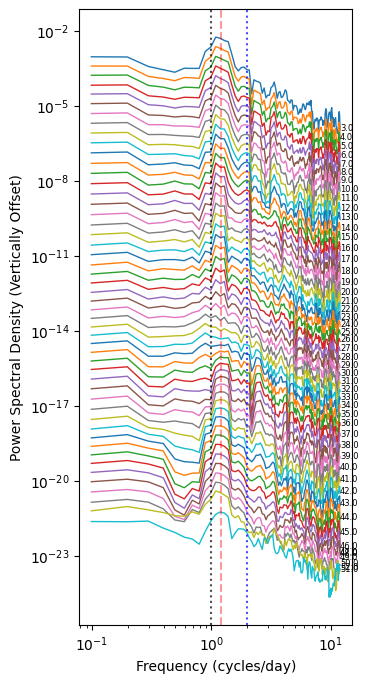

In [519]:
import numpy as np
import matplotlib.pyplot as plt
from multitaper import MTSpec

plt.figure(figsize=(12, 8))  # Increased height to give the stacked spectra room

plt.subplot(1,3,1)
# Choose a separation factor.
# Since it's a log scale, multiplying by 0.5 (or 10**-0.3) shifts it down nicely.
offset_factor = 0.4

for i in range(0, 50):
    P = 2
    dt = 1 / 24
    x = u_re2[:,i]/1000
    y = v_re2[:,i]/1000
    cv = x + 1j * y

    spec = MTSpec(cv - np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)

    # --- The Shift ---
    # Multiplying by (offset_factor ** i) shifts deeper layers progressively downward
    shifted_Sx = Sx * (offset_factor ** i)

    # Plot positive side using the shifted spectrum
    plt.loglog(fx[fx > 0], shifted_Sx[fx > 0], linewidth=1)
    x1 = fx[fx > 0]
    x2 = shifted_Sx[fx > 0]
    plt.text(x1[-1],x2[-1], np.round(dataB['depth'][i]), fontsize = 6)

# Reference vertical lines
plt.axvline(24 / 24, linestyle=':', color='black', alpha=0.7, label='Diurnal (1 cpd)')
plt.axvline(24 / 20, linestyle='--', color='red', alpha=0.4, label='Inertial (~1.2 cpd)')
plt.axvline(24 / 12, linestyle=':', color='blue', alpha=0.7, label='Semidiurnal (2 cpd)')

plt.ylabel('Power Spectral Density (Vertically Offset)')
plt.xlabel('Frequency (cycles/day)')



In [520]:
u_re2_nios = np.full((243, 52), np.nan)
v_re2_nios = np.full((243, 52), np.nan)

for i in range(0,44):

    dt = 1/24
    P = 2
    x = u_re2[:,i]/1000 - u_re2_tide[:,i]/1000
    y = v_re2[:,i]/1000 - v_re2_tide[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 10
    period = 20/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    u_re2_nios[:,i] = cvo.real
    v_re2_nios[:,i] = cvo.imag

In [521]:
u_re2_diurnal = np.full((243, 52), np.nan)
v_re2_diurnal = np.full((243, 52), np.nan)

for i in range(0,44):

    dt = 1/24
    P = 2
    x = u_re2[:,i]/1000 - u_re2_tide[:,i]/1000
    y = v_re2[:,i]/1000 - v_re2_tide[:,i]/1000
    cv = x + 1j * y
    spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    S = np.ravel(spec.spec)
    f = np.ravel(spec.freq)

    gamma = 3
    beta = 3
    period = 22/24 #period you're interested in. Here it's the M2 tide,
    omega = 2*np.pi/(period/dt)  #omega is a *radian* frequency

    _, psif = wt.morse_wavelet(len(cv),gamma,beta,[omega])  #morse_wavelet is expecting frequency to be an array
    psif = psif[0,0]
    cvo, _ = wt.morse_wavelet_transform(cv,gamma,beta,[omega],complex=True,boundary="mirror")
    u_re2_diurnal[:,i] = cvo.real
    v_re2_diurnal[:,i] = cvo.imag

(0.1, 8)

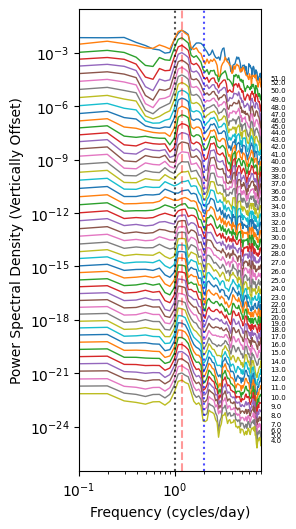

In [522]:
import numpy as np
import matplotlib.pyplot as plt
from multitaper import MTSpec

plt.figure(figsize=(8, 6))  # Increased height to give the stacked spectra room

plt.subplot(1,3,1)
# Choose a separation factor.
# Since it's a log scale, multiplying by 0.5 (or 10**-0.3) shifts it down nicely.
offset_factor = 0.4

for i in range(0, 49):
    P = 2
    dt = 1 / 24
    x = u_re2[:,49-i]/1000 - u_re2_tide[:,49-i]/1000
    y = v_re2[:,49-i]/1000 - v_re2_tide[:,49-i]/1000
    cv = x + 1j * y

    spec = MTSpec(cv - np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)

    # --- The Shift ---
    # Multiplying by (offset_factor ** i) shifts deeper layers progressively downward
    shifted_Sx = Sx * (offset_factor ** i)

    # Plot positive side using the shifted spectrum
    plt.loglog(fx[fx > 0], shifted_Sx[fx > 0], linewidth=1)
    x1 = fx[fx > 0]
    x2 = shifted_Sx[fx > 0]
    plt.text(x1[100],x2[100], np.round(dataB['depth'][49-i]), fontsize = 5)

# Reference vertical lines
plt.axvline(24 / 24, linestyle=':', color='black', alpha=0.7, label='Diurnal (1 cpd)')
plt.axvline(24 / 20, linestyle='--', color='red', alpha=0.4, label='Inertial (~1.2 cpd)')
plt.axvline(24 / 12, linestyle=':', color='blue', alpha=0.7, label='Semidiurnal (2 cpd)')

plt.ylabel('Power Spectral Density (Vertically Offset)')
plt.xlabel('Frequency (cycles/day)')
plt.xlim([0.1, 8])


(0.1, 8)

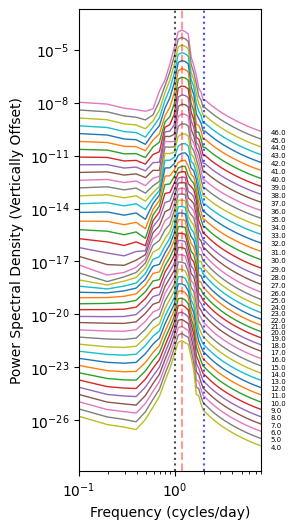

In [523]:
import numpy as np
import matplotlib.pyplot as plt
from multitaper import MTSpec

plt.figure(figsize=(8, 6))  # Increased height to give the stacked spectra room

plt.subplot(1,3,1)
# Choose a separation factor.
# Since it's a log scale, multiplying by 0.5 (or 10**-0.3) shifts it down nicely.
offset_factor = 0.4

for i in range(0, 49):
    P = 2
    dt = 1 / 24
    x = u_re2_nios[:,49-i]
    y = v_re2_nios[:,49-i]
    cv = x + 1j * y

    spec = MTSpec(cv - np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
    Sx = np.ravel(spec.spec)
    fx = np.ravel(spec.freq)

    # --- The Shift ---
    # Multiplying by (offset_factor ** i) shifts deeper layers progressively downward
    shifted_Sx = Sx * (offset_factor ** i)

    # Plot positive side using the shifted spectrum
    plt.loglog(fx[fx > 0], shifted_Sx[fx > 0], linewidth=1)
    x1 = fx[fx > 0]
    x2 = shifted_Sx[fx > 0]
    plt.text(x1[100],x2[100], np.round(dataB['depth'][49-i]), fontsize = 5)

# Reference vertical lines
plt.axvline(24 / 24, linestyle=':', color='black', alpha=0.7, label='Diurnal (1 cpd)')
plt.axvline(24 / 20, linestyle='--', color='red', alpha=0.4, label='Inertial (~1.2 cpd)')
plt.axvline(24 / 12, linestyle=':', color='blue', alpha=0.7, label='Semidiurnal (2 cpd)')

plt.ylabel('Power Spectral Density (Vertically Offset)')
plt.xlabel('Frequency (cycles/day)')
plt.xlim([0.1, 8])


In [524]:
import numpy as np

# Get the reconstructed u and v velocities
u_re = u_re2_nios
v_re = v_re2_nios

# Get the depths corresponding to the velocities (first 52 bins)
depths_for_shear = dataB['depth'][0:52]

# Calculate the vertical gradient of u (du/dz)
du_dz = np.gradient(u_re, depths_for_shear, axis=1)

# Calculate the vertical gradient of v (dv/dz)
dv_dz = np.gradient(v_re, depths_for_shear, axis=1)

# Calculate the shear of turbulence squared (S^2)
# S^2 = (du/dz)^2 + (dv/dz)^2
S2 = (du_dz**2) + (dv_dz**2)

print(f"Shape of du_dz: {du_dz.shape}")
print(f"Shape of dv_dz: {dv_dz.shape}")
print(f"Shape of S2 (Shear Squared): {S2.shape}")

# You can now further analyze or plot S2

Shape of du_dz: (243, 52)
Shape of dv_dz: (243, 52)
Shape of S2 (Shear Squared): (243, 52)


In [200]:
df_ctd20501_full

{'time': DatetimeIndex(['2005-01-14 12:09:14', '2005-01-14 15:14:13',
                '2005-01-14 18:06:46', '2005-01-14 19:58:30',
                '2005-01-14 22:33:31', '2005-01-15 00:24:20',
                '2005-01-15 03:21:12', '2005-01-15 06:22:56',
                '2005-01-15 09:57:33', '2005-01-15 14:45:22',
                '2005-01-15 18:49:08', '2005-01-15 18:53:39',
                '2005-01-15 21:28:23', '2005-01-16 00:43:47',
                '2005-01-16 03:16:53', '2005-01-16 07:22:12',
                '2005-01-16 07:27:06', '2005-01-16 10:49:54',
                '2005-01-16 12:56:12', '2005-01-16 15:10:35',
                '2005-01-16 23:37:15', '2005-01-16 23:41:52',
                '2005-01-17 08:31:56', '2005-01-18 00:36:56',
                '2005-01-18 01:07:08', '2005-01-18 03:32:41',
                '2005-01-18 06:23:22', '2005-01-18 09:15:14',
                '2005-01-18 12:29:04', '2005-01-18 15:31:21',
                '2005-01-18 18:59:41', '2005-01-19 10:06:58',


In [205]:
df_ctd20501['time']

DatetimeIndex(['2005-01-14 19:58:30', '2005-01-14 22:33:31',
               '2005-01-15 00:24:20', '2005-01-15 03:21:12',
               '2005-01-15 06:22:56', '2005-01-15 09:57:33',
               '2005-01-15 14:45:22', '2005-01-15 18:49:08',
               '2005-01-15 18:53:39', '2005-01-15 21:28:23',
               '2005-01-16 00:43:47', '2005-01-16 03:16:53',
               '2005-01-16 07:22:12', '2005-01-16 07:27:06',
               '2005-01-16 10:49:54', '2005-01-16 12:56:12',
               '2005-01-16 15:10:35', '2005-01-16 23:37:15',
               '2005-01-16 23:41:52', '2005-01-17 08:31:56',
               '2005-01-18 00:36:56', '2005-01-18 01:07:08',
               '2005-01-18 03:32:41', '2005-01-18 06:23:22',
               '2005-01-18 09:15:14', '2005-01-18 12:29:04',
               '2005-01-18 15:31:21', '2005-01-18 18:59:41',
               '2005-01-19 10:06:58', '2005-01-19 12:31:59',
               '2005-01-19 16:36:22', '2005-01-19 16:41:17',
               '2005-01-

In [326]:
from scipy.signal import savgol_filter

(0.0, 25.0)

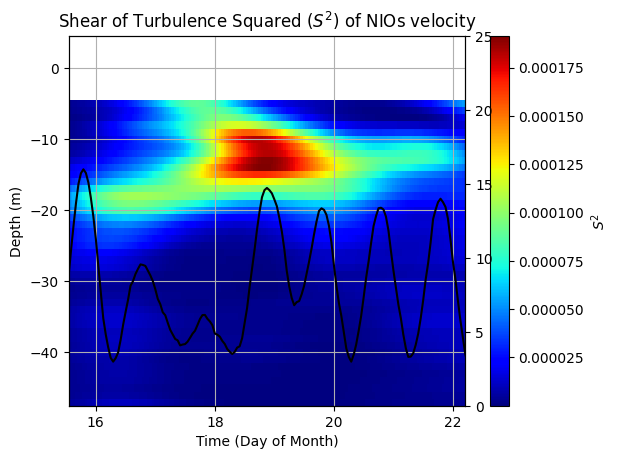

In [531]:
plt.pcolormesh(dataB['time'], dataB['depth'][0:52]-50, S2_nios[:,0:52].T, cmap='jet')
plt.colorbar(label='$S^2$')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d'))
plt.xlabel('Time (Day of Month)')
plt.ylabel('Depth (m)')
plt.title('Shear of Turbulence Squared ($S^2$) of NIOs velocity')


plt.xlim(dataB['time'][0], dataB['time'][160])
plt.grid()
plt.twinx()
plt.plot(cs['time'], savgol_filter(cs['wind_speed_kt'],20,2), color = 'k')
plt.ylim([0,25])

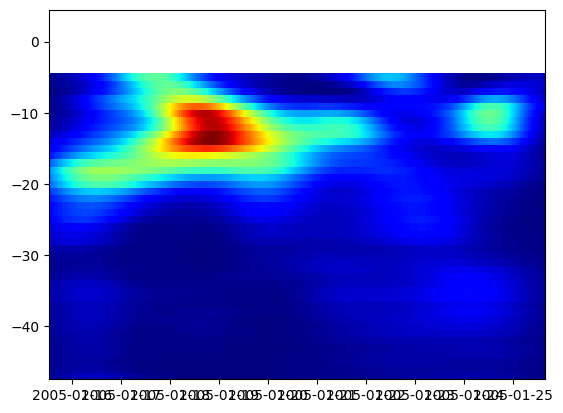

In [250]:
plt.pcolor(dataB['time'],dataB['depth'][0:52],S2.T, cmap = 'jet')


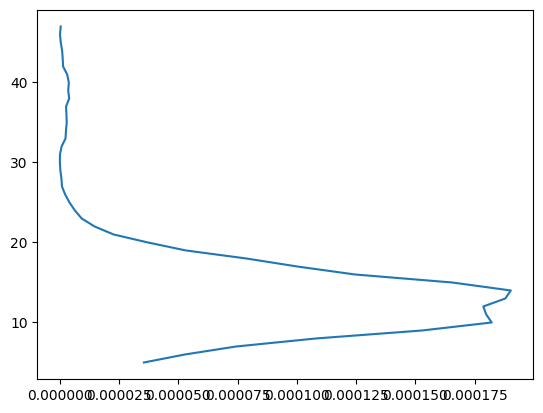

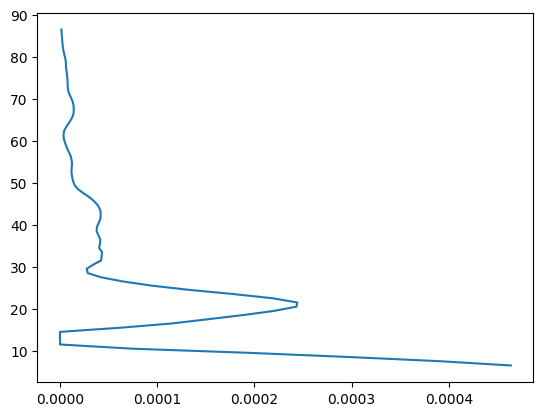

In [262]:
plt.figure()
S2_DEPTH = (dataB['depth'][0:52]-50)*-1
plt.plot(S2[76,:].T,S2_DEPTH)

plt.figure()
N2_DEPTH = plotting_p_mid
plt.plot(N2_matrix[26, :], N2_DEPTH)

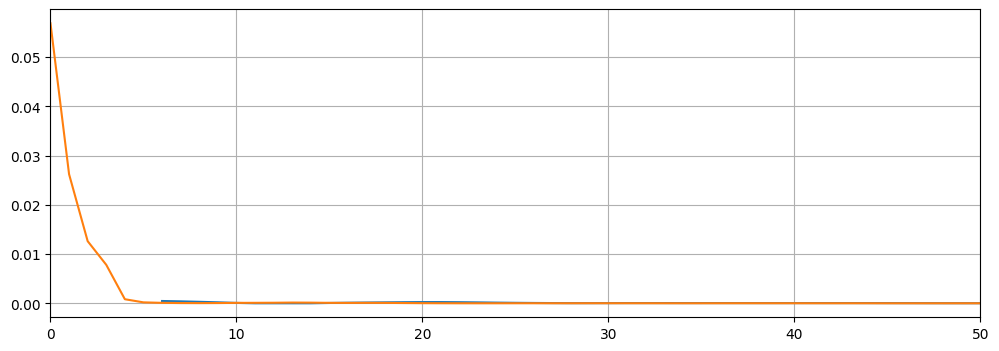

In [295]:
plt.figure(figsize=(12, 4))
x = N2_matrix[26, :]
y = S2[76,:]
y = np.flip(y)
plt.plot(x)
plt.plot(y)
plt.xlim([0,50])
plt.grid()

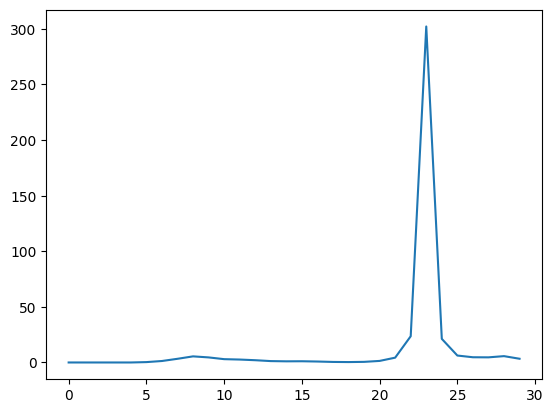

In [296]:
plt.plot(x[10:40]/y[0:30])


In [ ]:
plt.figure()
plt.plot(S2[76,:].T,S2_DEPTH)

plt.figure()
plt.plot(N2_matrix[26, :], N2_DEPTH)

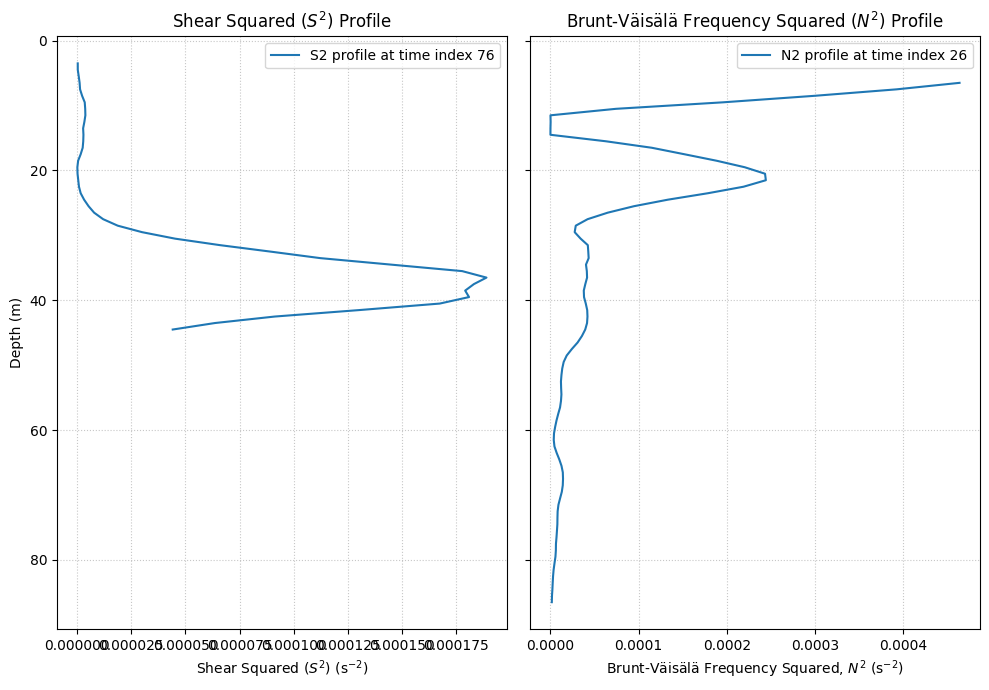

In [263]:
import numpy as np
import matplotlib.pyplot as plt

# Original depths for S2
s2_original_depths = dataB['depth'][0:52]

# Common depth axis (using plotting_p_mid as it covers a wider range and is already in mid-points)
common_depth_axis = plotting_p_mid

# Interpolate S2[76,:] onto the common_depth_axis
# Use left=np.nan and right=np.nan to fill non-overlapping depths with NaNs
s2_interpolated = np.interp(
    common_depth_axis,
    s2_original_depths,
    S2[76,:],
    left=np.nan,
    right=np.nan
)

# Create a figure with two subplots sharing the y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 7), sharey=True)

# Plot S2 profile
ax1.plot(s2_interpolated, common_depth_axis, label=f'S2 profile at time index 76')
ax1.set_xlabel(r'Shear Squared ($S^2$) (s$^{-2}$)')
ax1.set_ylabel('Depth (m)')
ax1.set_title(r'Shear Squared ($S^2$) Profile')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend()

# Plot N2 profile
ax2.plot(N2_matrix[26, :], common_depth_axis, label=f'N2 profile at time index 26')
ax2.set_xlabel(r'Brunt-Väisälä Frequency Squared, $N^2$ (s$^{-2}$)')
ax2.set_title(r'Brunt-Väisälä Frequency Squared ($N^2$) Profile')
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend()

# Invert y-axis for both subplots to show depth increasing downwards
ax1.invert_yaxis()
# ax2 shares y-axis with ax1, so it will also be inverted

plt.tight_layout()
plt.show()

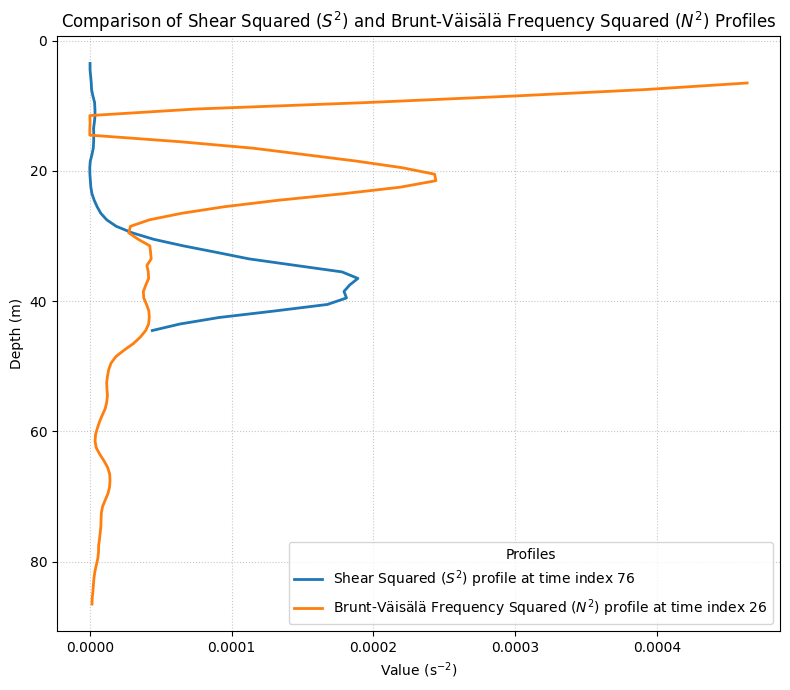

In [334]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure common_depth_axis and s2_interpolated are available from previous cells
# common_depth_axis is plotting_p_mid (0.5m to 99.5m)
# S2[76,:] data on its original depths (3m to 54m) is interpolated onto common_depth_axis

# Create a single figure and subplot
plt.figure(figsize=(8, 7))

# Plot S2 profile on the common depth axis
plt.plot(s2_interpolated, common_depth_axis, label=r'Shear Squared ($S^2$) profile at time index 76', linewidth=2)

# Plot N2 profile on the common depth axis
plt.plot(N2_matrix[26, :], common_depth_axis, label=r'Brunt-Väisälä Frequency Squared ($N^2$) profile at time index 26', linewidth=2)

# Formatting
plt.gca().invert_yaxis() # Invert y-axis to show depth increasing downwards
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title='Profiles', loc='lower right') # Place legend where it doesn't obscure data
plt.xlabel(r'Value (s$^{-2}$)') # A generic label as both S2 and N2 share units
plt.ylabel('Depth (m)')
plt.title(r'Comparison of Shear Squared ($S^2$) and Brunt-Väisälä Frequency Squared ($N^2$) Profiles')
plt.tight_layout()
plt.show()

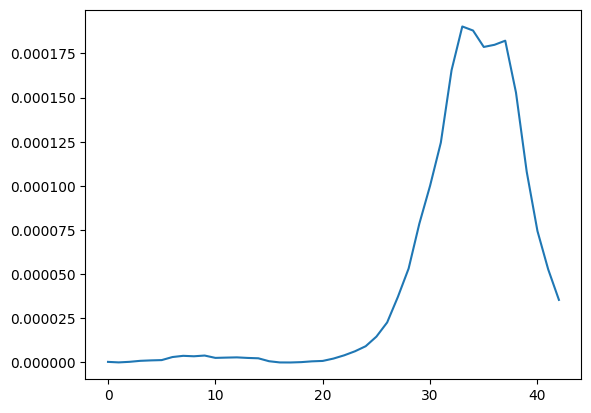

In [246]:
plt.plot(S2[76,:])

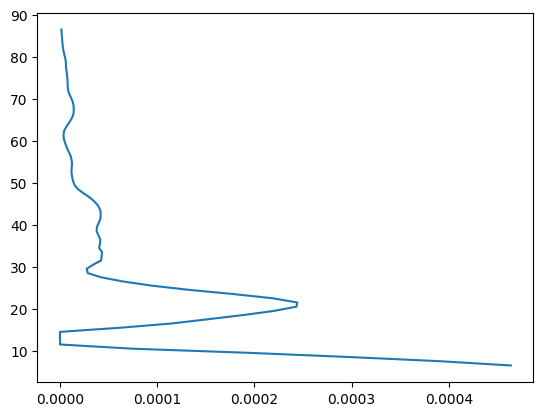

In [237]:
plt.plot(N2_matrix[26, :], plotting_p_mid)

<>:33: SyntaxWarning: invalid escape sequence '\s'
<>:33: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_781/1385654904.py:33: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Potential Density Anomaly, $\sigma_\\theta$ (kg/m$^3$)')
/tmp/ipykernel_781/1385654904.py:11: RuntimeWarning: Mean of empty slice
  mean_temp = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
/tmp/ipykernel_781/1385654904.py:12: RuntimeWarning: Mean of empty slice
  mean_sal = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)


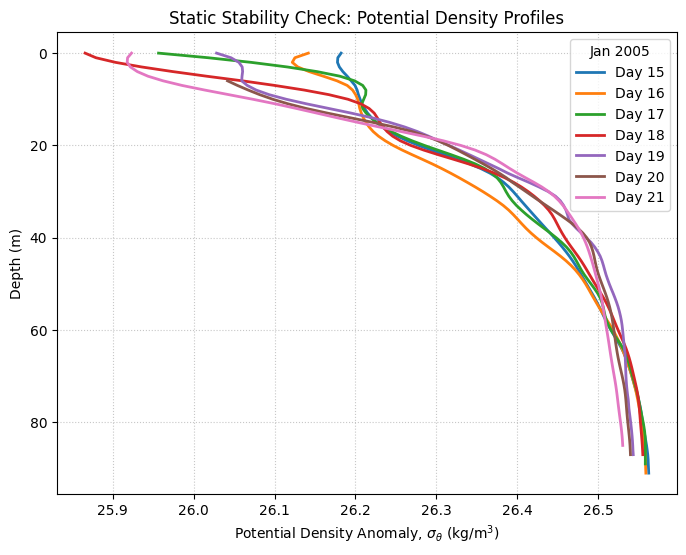

In [187]:
import numpy as np
import matplotlib.pyplot as plt
import gsw  # Ensure you have this installed: pip install gsw

plt.figure(figsize=(8, 6))

for i in range(15, 22):
    idx = np.where(df_ctd20501['time'].day == i)[0]

    # 1. Fetch the mean and smooth it (using your established parameters)
    mean_temp = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
    mean_sal = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)

    smoothed_temp = savgol_filter(mean_temp, window_length=11, polyorder=3)
    smoothed_sal = savgol_filter(mean_sal, window_length=11, polyorder=3)

    # 2. Approximate pressure from depth (1 dbar ≈ 1 meter)
    p = np.abs(df_ctd20501['depth'])

    # 3. Calculate TEOS-10 Potential Density Anomaly
    # Using the coordinates for Concepción (-73.0 W, -36.4 S)
    SA = gsw.SA_from_SP(smoothed_sal, p, -73.0, -36.4)
    CT = gsw.CT_from_t(SA, smoothed_temp, p)
    sigma0 = gsw.sigma0(SA, CT)

    # 4. Plot the Density Profile
    plt.plot(sigma0, df_ctd20501['depth'], label=f'Day {i}', linewidth=2)

# Formatting
plt.gca().invert_yaxis()
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title="Jan 2005")
plt.xlabel('Potential Density Anomaly, $\sigma_\\theta$ (kg/m$^3$)')
plt.ylabel('Depth (m)')
plt.title('Static Stability Check: Potential Density Profiles')
plt.show()

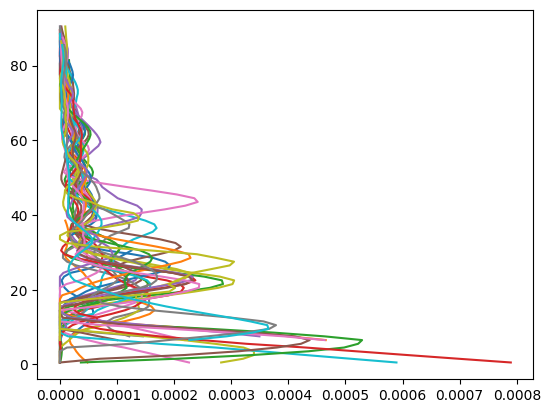

In [231]:
for i in range(0,30):
  plt.plot(N2_matrix[i, :], plotting_p_mid)

Let's visualize an original and a filtered profile to see the effect of the bandpass filter. We will plot the profile at a specific depth (e.g., depth index 20, which corresponds to `dataB['depth'][20]` = 23m) to observe the time series.

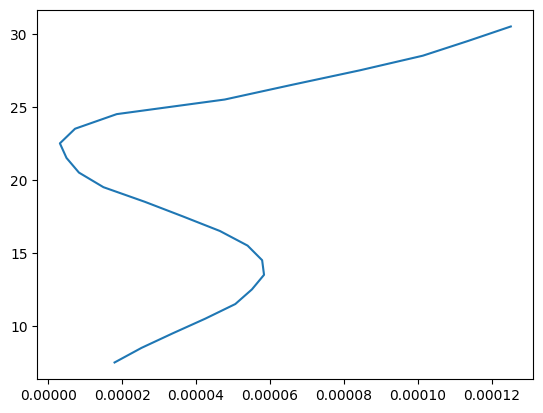

In [233]:

plt.plot(N2_matrix[0, :], plotting_p_mid)

/tmp/ipykernel_781/3541445638.py:65: RuntimeWarning: Mean of empty slice
  mean_temp_raw = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
/tmp/ipykernel_781/3541445638.py:66: RuntimeWarning: Mean of empty slice
  mean_sal_raw = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)


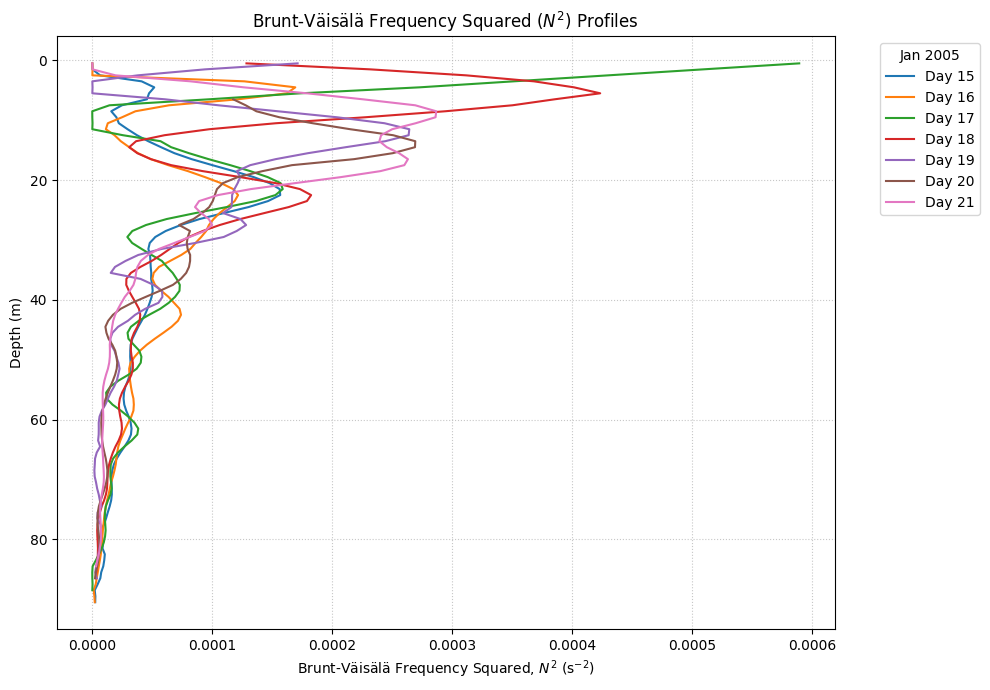


Interpretation of Brunt-Väisälä Frequency Squared (N^2):
The Brunt-Väisälä frequency squared ($N^2$) is a key indicator of ocean stratification. It represents the natural frequency at which a vertically displaced water parcel will oscillate due to buoyancy forces.
• Positive $N^2$ values indicate a statically stable water column, where lighter water overlies denser water. Higher $N^2$ means stronger stratification and greater resistance to vertical mixing.
• Zero $N^2$ indicates neutral stability.
• Negative $N^2$ values indicate static instability (density inversions), where denser water overlies lighter water, leading to convection and mixing. The stabilization process applied before calculating $N^2$ aims to remove these physical instabilities, ensuring only positive or zero $N^2$ values are typically plotted for a 'stable' interpretation.
These profiles show how $N^2$ varies with depth for different days in January 2005, highlighting changes in stratification over time.


In [227]:
import numpy as np
import matplotlib.pyplot as plt
import gsw
from scipy.signal import savgol_filter
import pandas as pd # Ensure pandas is imported for DatetimeIndex if needed

# 1. Define the stabilization function (copied from JMiBvljMOS8j for self-containment)
def stabilize_water_column(depth, temp, salt, lon=-73.0, lat=-36.4):
    """
    Performs a 1D convective adjustment to ensure strict static stability.
    Averages Temperature and Salinity of adjacent unstable layers.
    """
    t_adj = temp.copy()
    s_adj = salt.copy()
    p = np.abs(depth) # Pressure in dbar is roughly depth in meters

    stable = False
    # Keep checking and mixing until the whole column is perfectly stable
    while not stable:
        stable = True

        # Calculate current density
        SA = gsw.SA_from_SP(s_adj, p, lon, lat)
        CT = gsw.CT_from_t(SA, t_adj, p)
        sigma = gsw.sigma0(SA, CT)

        # Scan from surface to bottom
        for k in range(len(sigma) - 1):
            # If the layer below is lighter than the layer above (Inversion!)
            if sigma[k+1] < sigma[k]:
                # Mix the two layers
                t_mean = (t_adj[k] + t_adj[k+1]) / 2.0
                s_mean = (s_adj[k] + s_adj[k+1]) / 2.0

                # Apply the mixed properties back to both layers
                t_adj[k], t_adj[k+1] = t_mean, t_mean
                s_adj[k], s_adj[k+1] = s_mean, s_mean

                # We changed something, so we must re-check the whole column
                stable = False
    return t_adj, s_adj

# Constants
lon = -73.0
lat = -36.4
depths = df_ctd20501['depth'].values
p_dbar = np.abs(depths) # Pressure in dbar is approximately depth in meters

# Parameters for Savitzky-Golay filter
window_length = 11 # Must be odd
polyorder = 3

plt.figure(figsize=(10, 7))

# Loop through each day (15 to 21) for which data is typically processed
for i in range(15, 22):
    idx = np.where(df_ctd20501['time'].day == i)[0]

    if len(idx) == 0:
        print(f"No data for day {i}, skipping.")
        continue

    # 1. Extract raw temperature and salinity for the current day's profiles
    # Mean of profiles for the current day
    mean_temp_raw = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
    mean_sal_raw = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)

    # 2. Smooth the profiles using Savitzky-Golay filter
    # Interpolate NaNs before smoothing for robustness
    temp_interp = pd.Series(mean_temp_raw).interpolate(method='linear', limit_area='inside').values
    sal_interp = pd.Series(mean_sal_raw).interpolate(method='linear', limit_area='inside').values

    # Handle cases where interpolation might still leave NaNs or if entire profile is NaN
    if np.all(np.isnan(temp_interp)) or np.all(np.isnan(sal_interp)):
        print(f"Skipping day {i} due to insufficient valid data for smoothing.")
        continue

    smoothed_temp = savgol_filter(temp_interp, window_length=window_length, polyorder=polyorder, mode='interp')
    smoothed_sal = savgol_filter(sal_interp, window_length=window_length, polyorder=polyorder, mode='interp')

    # 3. Enforce strict static stability
    stable_temp, stable_sal = stabilize_water_column(depths, smoothed_temp, smoothed_sal, lon, lat)

    # Filter out NaNs from stabilized profiles and corresponding pressures for gsw calculation
    valid_indices = ~np.isnan(stable_temp) & ~np.isnan(stable_sal) & ~np.isnan(p_dbar)
    valid_p_dbar = p_dbar[valid_indices]
    valid_stable_temp = stable_temp[valid_indices]
    valid_stable_sal = stable_sal[valid_indices]

    if np.sum(valid_indices) > 1: # Need at least 2 valid points for Nsquared
        # 4. Calculate Absolute Salinity (SA) and Conservative Temperature (CT)
        SA = gsw.SA_from_SP(valid_stable_sal, valid_p_dbar, lon, lat)
        CT = gsw.CT_from_t(SA, valid_stable_temp, valid_p_dbar)

        # 5. Calculate Brunt-Väisälä Frequency Squared (N^2)
        N2, p_mid = gsw.Nsquared(SA, CT, valid_p_dbar, lat=lat)

        # Plot the N^2 profile
        plt.plot(N2, p_mid, label=f'Day {i}', linewidth=1.5)
    else:
        print(f"Not enough valid data points for N^2 calculation for day {i} after stabilization.")

# 6. Plot formatting
plt.gca().invert_yaxis()
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title="Jan 2005", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel(r'Brunt-Väisälä Frequency Squared, $N^2$ (s$^{-2}$)')
plt.ylabel('Depth (m)')
plt.title(r'Brunt-Väisälä Frequency Squared ($N^2$) Profiles')
plt.tight_layout()
plt.show()

print("\nInterpretation of Brunt-Väisälä Frequency Squared (N^2):")
print(r"The Brunt-Väisälä frequency squared ($N^2$) is a key indicator of ocean stratification. It represents the natural frequency at which a vertically displaced water parcel will oscillate due to buoyancy forces.")
print(r"• Positive $N^2$ values indicate a statically stable water column, where lighter water overlies denser water. Higher $N^2$ means stronger stratification and greater resistance to vertical mixing.")
print(r"• Zero $N^2$ indicates neutral stability.")
print(r"• Negative $N^2$ values indicate static instability (density inversions), where denser water overlies lighter water, leading to convection and mixing. The stabilization process applied before calculating $N^2$ aims to remove these physical instabilities, ensuring only positive or zero $N^2$ values are typically plotted for a 'stable' interpretation.")
print(r"These profiles show how $N^2$ varies with depth for different days in January 2005, highlighting changes in stratification over time.")

In [104]:
import pandas as pd
import numpy as np

# Ensure dataB['time'] is a DatetimeIndex
if not isinstance(dataB['time'], pd.DatetimeIndex):
    dataB['time'] = pd.to_datetime(dataB['time'])

# Extract the date part from the time index
dates = dataB['time'].date

# Create a DataFrame to easily group by date
# The S2 data has shape (ntime, ndepth), so we need to transpose it for easier grouping
# or iterate through the dates

# Get unique dates in chronological order
unique_dates = sorted(list(set(dates)))

# Initialize a list to store daily averaged S2 profiles
s2_daily_avg_list = []

# Iterate through each unique date and calculate the average S2
for current_date in unique_dates:
    # Find all indices in the original data that correspond to the current date
    indices_for_day = [i for i, d in enumerate(dates) if d == current_date]

    if indices_for_day:
        # Select S2 data for the current day and calculate the mean along the time axis (axis=0)
        daily_mean_s2 = np.nanmean(S2[indices_for_day, :], axis=0)
        s2_daily_avg_list.append(daily_mean_s2)
    else:
        # If no data for a day, append NaNs or handle as appropriate
        s2_daily_avg_list.append(np.full(S2.shape[1], np.nan)) # Append NaN array with same depth dimension

# Convert the list of daily averages into a NumPy array (matrix)
S2_daily_avg = np.array(s2_daily_avg_list)

# Optionally, create a new DatetimeIndex for the daily averages if needed for plotting/analysis
daily_time_index = pd.to_datetime(unique_dates)

print(f"Shape of S2_daily_avg (days x depths): {S2_daily_avg.shape}")
print(f"Number of unique days: {len(daily_time_index)}")
print("First few rows of S2_daily_avg (first 5 depths):\n", S2_daily_avg[:5, :5])


Shape of S2_daily_avg (days x depths): (11, 52)
Number of unique days: 11
First few rows of S2_daily_avg (first 5 depths):
 [[9.25209100e-06 5.22189505e-06 4.29700843e-06 3.72928084e-06
  8.11252942e-06]
 [3.05507068e-05 2.07674722e-05 2.40450974e-05 2.65394871e-05
  2.52511318e-05]
 [8.88356277e-06 5.82273205e-06 6.62913232e-06 7.57022163e-06
  7.53664018e-06]
 [5.59674556e-06 3.59231691e-06 9.11387441e-06 9.03153475e-06
  7.54285402e-06]
 [2.24081367e-06 1.40084148e-06 3.99864177e-06 3.04964090e-06
  2.45178182e-06]]


(40.0, 50.0)

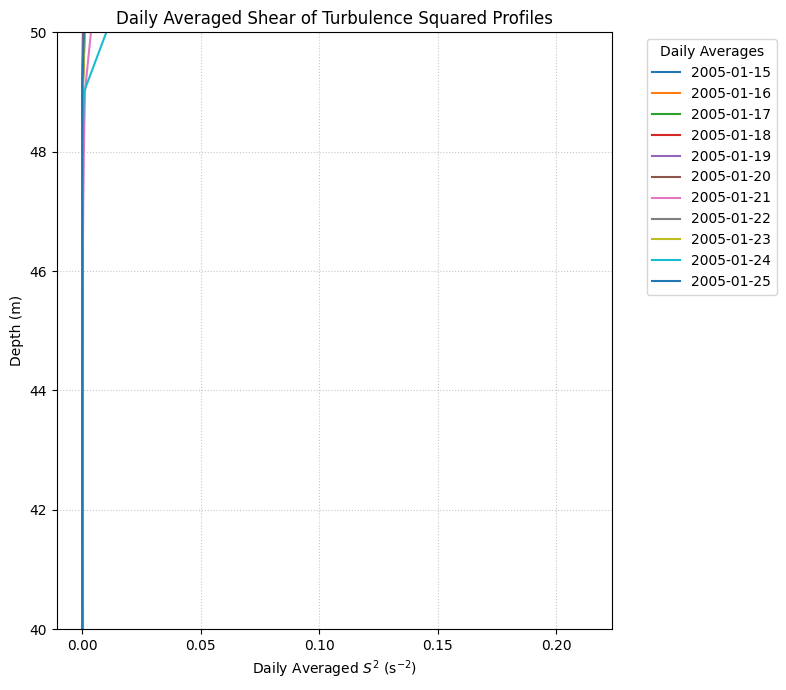

In [108]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

plt.figure(figsize=(8, 7))

# Loop through each day in the S2_daily_avg matrix
for i, day_s2_profile in enumerate(S2_daily_avg):
    # daily_time_index contains datetime objects for each day
    current_date_str = daily_time_index[i].strftime('%Y-%m-%d')
    plt.plot(day_s2_profile, depths_for_shear, label=current_date_str)

plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title="Daily Averages", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel('Daily Averaged $S^2$ (s$^{-2}$)')
plt.ylabel('Depth (m)')
plt.title('Daily Averaged Shear of Turbulence Squared Profiles')
plt.tight_layout()
plt.ylim([40,50])

In [46]:
dataB['time']

DatetimeIndex(['2005-01-15 13:00:00', '2005-01-15 14:00:00',
               '2005-01-15 15:00:00', '2005-01-15 16:00:00',
               '2005-01-15 17:00:00', '2005-01-15 18:00:00',
               '2005-01-15 19:00:00', '2005-01-15 20:00:00',
               '2005-01-15 21:00:00', '2005-01-15 22:00:00',
               ...
               '2005-01-25 06:00:00', '2005-01-25 07:00:00',
               '2005-01-25 08:00:00', '2005-01-25 09:00:00',
               '2005-01-25 10:00:00', '2005-01-25 11:00:00',
               '2005-01-25 12:00:00', '2005-01-25 13:00:00',
               '2005-01-25 14:00:00', '2005-01-25 15:00:00'],
              dtype='datetime64[ns]', name='datetime', length=243, freq='h')

In [17]:
import gsw
import numpy as np

def stabilize_water_column(depth, temp, salt, lon=-73.0, lat=-36.4):
    """
    Performs a 1D convective adjustment to ensure strict static stability.
    Averages Temperature and Salinity of adjacent unstable layers.
    """
    t_adj = temp.copy()
    s_adj = salt.copy()
    p = np.abs(depth) # Pressure in dbar is roughly depth in meters

    stable = False
    # Keep checking and mixing until the whole column is perfectly stable
    while not stable:
        stable = True

        # Calculate current density
        SA = gsw.SA_from_SP(s_adj, p, lon, lat)
        CT = gsw.CT_from_t(SA, t_adj, p)
        sigma = gsw.sigma0(SA, CT)

        # Scan from surface to bottom
        for k in range(len(sigma) - 1):
            # If the layer below is lighter than the layer above (Inversion!)
            if sigma[k+1] < sigma[k]:
                # Mix the two layers
                t_mean = (t_adj[k] + t_adj[k+1]) / 2.0
                s_mean = (s_adj[k] + s_adj[k+1]) / 2.0

                # Apply the mixed properties back to both layers
                t_adj[k], t_adj[k+1] = t_mean, t_mean
                s_adj[k], s_adj[k+1] = s_mean, s_mean

                # We changed something, so we must re-check the whole column
                stable = False

    return t_adj, s_adj

In [18]:
smoothed_temp = savgol_filter(mean_temp, window_length=11, polyorder=3)
smoothed_sal = savgol_filter(mean_sal, window_length=11, polyorder=3)

    # NEW STEP: Enforce strict static stability
stable_temp, stable_salt = stabilize_water_column(
    df_ctd20501['depth'].values,
    smoothed_temp,
    smoothed_sal
    )

<>:71: SyntaxWarning: invalid escape sequence '\s'
<>:71: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_781/4068637763.py:71: SyntaxWarning: invalid escape sequence '\s'
  ax3.set_xlabel('$\sigma_\\theta$ (kg/m$^3$)')
/tmp/ipykernel_781/4068637763.py:38: RuntimeWarning: Mean of empty slice
  mean_temp = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
/tmp/ipykernel_781/4068637763.py:39: RuntimeWarning: Mean of empty slice
  mean_sal = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)


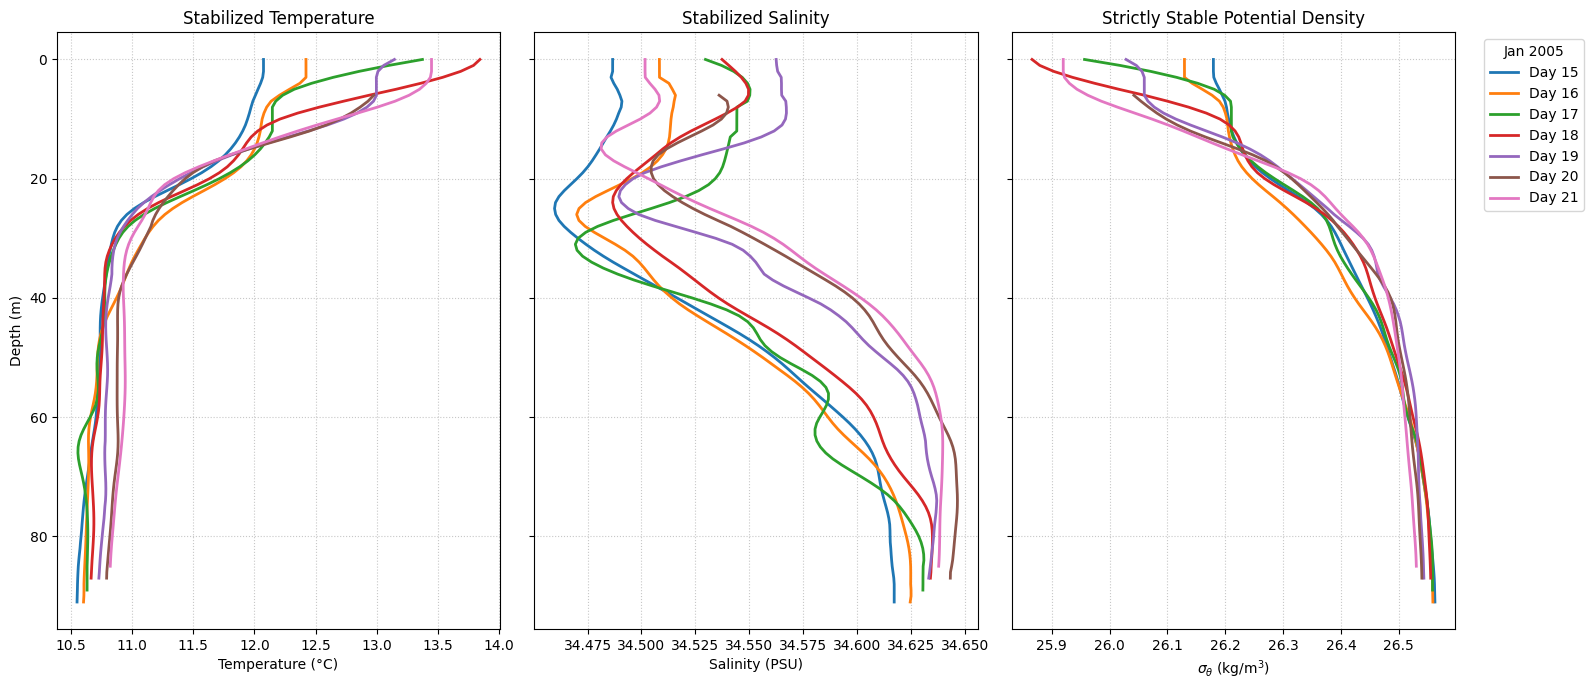

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import gsw

# 1. Define the stabilization function
def stabilize_water_column(depth, temp, salt, lon=-73.0, lat=-36.4):
    t_adj = temp.copy()
    s_adj = salt.copy()
    p = np.abs(depth)

    stable = False
    while not stable:
        stable = True
        SA = gsw.SA_from_SP(s_adj, p, lon, lat)
        CT = gsw.CT_from_t(SA, t_adj, p)
        sigma = gsw.sigma0(SA, CT)

        for k in range(len(sigma) - 1):
            if sigma[k+1] < sigma[k]: # Inversion detected
                t_mean = (t_adj[k] + t_adj[k+1]) / 2.0
                s_mean = (s_adj[k] + s_adj[k+1]) / 2.0
                t_adj[k], t_adj[k+1] = t_mean, t_mean
                s_adj[k], s_adj[k+1] = s_mean, s_mean
                stable = False
    return t_adj, s_adj

# 2. Set up the three-panel figure
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
depths = df_ctd20501['depth'].values
p = np.abs(depths)

# 3. Process and plot each day
for i in range(15, 22):
    idx = np.where(df_ctd20501['time'].day == i)[0]

    # Extract mean
    mean_temp = np.nanmean(df_ctd20501['temp'][:, idx], axis=1)
    mean_sal = np.nanmean(df_ctd20501['sal'][:, idx], axis=1)

    # Smooth
    smoothed_temp = savgol_filter(mean_temp, window_length=11, polyorder=3)
    smoothed_sal = savgol_filter(mean_sal, window_length=11, polyorder=3)

    # Stabilize
    stable_temp, stable_salt = stabilize_water_column(depths, smoothed_temp, smoothed_sal)

    # Calculate final density
    SA = gsw.SA_from_SP(stable_salt, p, -73.0, -36.4)
    CT = gsw.CT_from_t(SA, stable_temp, p)
    sigma0 = gsw.sigma0(SA, CT)

    # Plot
    ax1.plot(stable_temp, depths, linewidth=2, label=f'Day {i}')
    ax2.plot(stable_salt, depths, linewidth=2, label=f'Day {i}')
    ax3.plot(sigma0, depths, linewidth=2, label=f'Day {i}')

# 4. Formatting
ax1.invert_yaxis()
for ax in (ax1, ax2, ax3):
    ax.grid(True, linestyle=':', alpha=0.7)

ax1.set_title('Stabilized Temperature')
ax1.set_xlabel('Temperature (°C)')
ax1.set_ylabel('Depth (m)')

ax2.set_title('Stabilized Salinity')
ax2.set_xlabel('Salinity (PSU)')

ax3.set_title('Strictly Stable Potential Density')
ax3.set_xlabel('$\sigma_\\theta$ (kg/m$^3$)')
ax3.legend(title="Jan 2005", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()